Patch terrain EDA: scale, availability and morphology

First cycle of [outline.md](../../outline.md). What complete terrain patches
exist at 300, 600 and 960 m, and how does their character vary?

This is descriptive exploration, not model training or validated analog retrieval.
Earth uses the natural screen plus five finite terrain channels. Lunar views
retain their separate complete-feature masks. All windows are nonoverlapping,
anchored at the grid's upper-left corner; right/bottom remainder strips are omitted.
Neighboring windows and windows across scales are not independent observations.
Counts depend on size, origin, stride and policy; they are not a search over all
possible window placements. Local elevation SD has a 330 m neighborhood.

In [8]:
import hashlib
import json
import sys
from datetime import UTC, datetime
from importlib.metadata import version
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import rasterio
from IPython.display import Image, Markdown, display
from matplotlib.figure import Figure
from rasterio.windows import Window

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'outline.md').exists())
sys.path.insert(0, str(ROOT / 'notebooks'))
from inspection import check_input, complete_blocks, file_hash, verify_run
from patch_analysis import measure_patch

NOTEBOOK = ROOT / 'notebooks/exploration/15_patch_terrain_eda.ipynb'
RUN_IDS = {
    'earth_terrain_landcover': '20261028T063142045472Z_9d6d3b',
    'lunar_terrain_views': '20261028T084443441751Z_1a794f',
}
SIZES_M = [300, 600, 960]
SPACING_M = 30
CHANNELS = ['elevation_m', 'relative_elevation_m', 'slope_deg',
            'laplacian_per_m', 'local_elevation_std_m']
DESCRIPTORS = {
    'slope_median_deg': 'Patch median slope (degrees)',
    'slope_p90_deg': 'Patch P90 slope (degrees)',
    'relief_m': 'Patch maximum minus minimum elevation (m)',
    'central_relief_m': 'Patch P95 minus P05 elevation (m)',
    'local_sd_median_m': 'Patch median local elevation SD (m; 330 m window)',
}
GROUP = ['body', 'region', 'population', 'size_m']
OUT = ROOT / 'data/processed/analysis' / (
    'patch-eda-' + datetime.now(UTC).strftime('%Y%m%dT%H%M%S%fZ'))
OUT.mkdir(parents=True, exist_ok=False)
runs = {stage: ROOT / 'data/processed' / stage / run for stage, run in RUN_IDS.items()}
expected: dict[str, str] = {}
evidence: dict[str, str] = {}
for run in runs.values():
    expected.update(verify_run(run))
    evidence[str(run / 'provenance.json')] = file_hash(run / 'provenance.json')
source = '\n'.join(cell.source for cell in nbformat.read(NOTEBOOK, as_version=4).cells)
provenance: dict[str, Any] = {
    'status': 'running', 'notebook': str(NOTEBOOK.relative_to(ROOT)),
    'notebook_source_sha256': hashlib.sha256(source.encode()).hexdigest(),
    'helpers': {name: file_hash(ROOT / 'notebooks' / name)
                for name in ['inspection.py', 'patch_analysis.py']},
    'runs': RUN_IDS, 'patch_sizes_m': SIZES_M, 'grid_spacing_m': SPACING_M,
    'eligibility_channels': CHANNELS, 'origin_row_col': [0, 0],
    'stride': 'patch side; nonoverlapping within each scale',
    'edge_policy': 'omit right/bottom remainders; count excluded eligible cells',
    'quantile_method': 'linear', 'gallery_quantiles_of_patch_p90_slope': [.05, .5, .95],
    'python': sys.version,
    'software': {name: version(name) for name in
                 ['numpy', 'pandas', 'scipy', 'rasterio', 'matplotlib', 'nbformat']},
}
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})


def read_layer(path: Path) -> tuple[np.ndarray, tuple[Any, ...]]:
    """Read a hash-verified layer with decoded values and its grid identity."""
    with rasterio.open(check_input(path, expected, evidence)) as dataset:
        assert dataset.count == 1 and dataset.scales == (1.,) and dataset.offsets == (0.,), path
        transform = dataset.transform
        assert transform.a == SPACING_M and transform.e == -SPACING_M
        assert transform.b == transform.d == 0 and dataset.crs is not None
        values = dataset.read(1, masked=True).astype('float32').filled(np.nan)
        assert not np.isinf(values).any(), path
        return values, (dataset.shape, transform, dataset.crs)


def save_figure(fig: Figure, name: str) -> None:
    fig.savefig(OUT / f'{name}.png', bbox_inches='tight')
    fig.savefig(OUT / f'{name}.pdf', bbox_inches='tight')
    display(Image(filename=str(OUT / f'{name}.png')))
    plt.close(fig)


print('Inputs:', RUN_IDS)
print('Output:', OUT)

Inputs: {'earth_terrain_landcover': '20261028T063142045472Z_9d6d3b', 'lunar_terrain_views': '20261028T084443441751Z_1a794f'}
Output: .\data\processed\analysis\patch-eda-20261102T143556253618Z


# Inventory complete windows and measure physical descriptors

Each row of patch_metrics.csv is one complete square at a specified site, view,
scale and row/column origin. Bounds and centers use the site's projected CRS,
recorded in site_grids.json. Areas are projected grid areas, not independent
sampling areas. Elevation mean is retained for context and display centering,
not used as a cross-body similarity feature.

Inventory denominators are explicit: all lattice windows, windows intersecting
the ROI, eligible cells, and eligible cells retained inside complete windows.
Eligibility requires all five channels even though only three are summarized
here; this preserves the accepted EDA population policy.

In [9]:
earth_folders = sorted((runs['earth_terrain_landcover'] / 'earth').glob('*/grid_30m'))
moon_folders = sorted((runs['lunar_terrain_views'] / 'moon').iterdir())
assert len(earth_folders) == 3 and len(moon_folders) == 7
site_specs = [('earth', p.parent.name, p) for p in earth_folders]
site_specs += [('moon', p.name, p) for p in moon_folders]
inventory_rows: list[dict[str, Any]] = []
origin_rows: list[dict[str, Any]] = []
patch_rows: list[dict[str, Any]] = []
grids: dict[str, Any] = {}
layer_folders: dict[tuple[str, str], Path] = {}
strict_mask_paths: dict[str, Path] = {}

for body, region, folder in site_specs:
    populations: dict[str, tuple[dict[str, np.ndarray], np.ndarray]] = {}
    screen = None
    if body == 'earth':
        screen, grid = read_layer(folder / 'natural_screen_mask.tif')
        inside = np.isfinite(screen)
        assert set(np.unique(screen[inside])) <= {0, 1}
        views = [('natural_screen', folder)]
    else:
        coverage, grid = read_layer(folder / 'quality/source_coverage_fraction.tif')
        inside = np.isfinite(coverage) & (coverage > 0)
        views = [(view, folder / view) for view in ['full_context', 'image_supported']]
        strict_mask_paths[region] = folder / 'quality/image_supported_complete_feature_mask.tif'
    for population, layer_folder in views:
        layers = {}
        for channel in CHANNELS:
            layers[channel], layer_grid = read_layer(layer_folder / f'{channel}.tif')
            assert layer_grid == grid, (region, channel)
        eligible = inside & np.logical_and.reduce([np.isfinite(a) for a in layers.values()])
        if body == 'earth':
            assert screen is not None
            eligible &= screen == 1
        else:
            saved_mask, mask_grid = read_layer(folder / 'quality' / f'{population}_complete_feature_mask.tif')
            assert mask_grid == grid and np.array_equal(eligible, saved_mask == 1)
        populations[population] = (layers, eligible)
        layer_folders[region, population] = layer_folder

    shape, transform, crs = grid
    grids[region] = {'body': body, 'shape': shape, 'transform': list(transform),
                     'crs_wkt': crs.to_wkt(), 'units': 'projected meters'}
    for population, (layers, eligible) in populations.items():
        assert eligible.any(), (region, population)
        for size_m in SIZES_M:
            side = size_m // SPACING_M
            accepted = complete_blocks(eligible, side)
            block_rows, block_cols = accepted.shape
            height, width = block_rows * side, block_cols * side
            roi_windows = inside[:height, :width].reshape(block_rows, side, block_cols, side).any(axis=(1, 3))
            eligible_cells = int(eligible.sum())
            lattice_cells = int(eligible[:height, :width].sum())
            retained_cells = int(accepted.sum()) * side * side
            for origin_row in [0, side // 2]:
                for origin_col in [0, side // 2]:
                    shifted = complete_blocks(eligible[origin_row:, origin_col:], side)
                    shifted_count = int(shifted.sum())
                    origin_rows.append({
                        'body': body, 'region': region, 'population': population, 'size_m': size_m,
                        'origin_row': origin_row, 'origin_col': origin_col, 'stride_cells': side,
                        'complete_windows': shifted_count,
                        'retained_pct_of_eligible_cells': 100 * shifted_count * side**2 / eligible_cells,
                    })
            inventory_rows.append({
                'body': body, 'region': region, 'population': population, 'size_m': size_m,
                'side_cells': side, 'stride_cells': side, 'origin_row': 0, 'origin_col': 0,
                'grid_rows': shape[0], 'grid_cols': shape[1], 'lattice_windows': accepted.size,
                'roi_intersecting_windows': int(roi_windows.sum()), 'complete_windows': int(accepted.sum()),
                'complete_pct_of_roi_windows': 100 * int(accepted.sum()) / int(roi_windows.sum()),
                'roi_cells': int(inside.sum()), 'eligible_cells': eligible_cells,
                'retained_cells': retained_cells, 'retained_pct_of_eligible_cells': 100 * retained_cells / eligible_cells,
                'eligible_cells_in_rejected_windows': lattice_cells - retained_cells,
                'eligible_cells_in_edge_remainders': eligible_cells - lattice_cells,
                'retained_projected_km2': retained_cells * SPACING_M**2 / 1e6,
            })
            for block_row, block_col in np.argwhere(accepted):
                row, col = int(block_row) * side, int(block_col) * side
                window = np.s_[row:row + side, col:col + side]
                metrics = measure_patch(layers['elevation_m'][window], layers['slope_deg'][window],
                                        layers['local_elevation_std_m'][window])
                left, top = transform * (col, row)
                right, bottom = transform * (col + side, row + side)
                patch_rows.append({
                    'body': body, 'region': region, 'population': population, 'size_m': size_m,
                    'patch_id': f'{region}:{population}:{size_m}:{row}:{col}',
                    'row': row, 'col': col, 'side_cells': side,
                    'left_m': left, 'right_m': right, 'bottom_m': bottom, 'top_m': top,
                    'center_x_m': (left + right) / 2, 'center_y_m': (bottom + top) / 2, **metrics,
                })
    print(region, {p: int(mask.sum()) for p, (_, mask) in populations.items()})

inventory = pd.DataFrame(inventory_rows)
patches = pd.DataFrame(patch_rows)
assert len(inventory) == 51 and not patches['patch_id'].duplicated().any()
assert int(inventory['complete_windows'].sum()) == len(patches)
assert np.isfinite(patches[list(DESCRIPTORS)].to_numpy(dtype=float)).all()
inventory.to_csv(OUT / 'inventory.csv', index=False)
origins = pd.DataFrame(origin_rows)
origins.to_csv(OUT / 'origin_sensitivity.csv', index=False)
patches.to_csv(OUT / 'patch_metrics.csv', index=False)
(OUT / 'site_grids.json').write_text(json.dumps(grids, indent=2), encoding='utf-8')
display(inventory[['region', 'population', 'size_m', 'complete_windows',
                   'retained_pct_of_eligible_cells', 'retained_projected_km2']])
print(f'{len(patches):,} patch records across views and scales; not independent samples.')

atacama_san_pedro {'natural_screen': 5534778}
lanzarote {'natural_screen': 402999}
northern_arizona {'natural_screen': 3431763}
A3CLR22_10_Leibnitz_Beta_Plateau {'full_context': 273529, 'image_supported': 195828}
A3CLR22_11_Malapert_Massif {'full_context': 475410, 'image_supported': 392617}
A3CLR22_12_deGerlache_Kocher_Massif {'full_context': 430336, 'image_supported': 372363}
A3CLR22_2_Haworth {'full_context': 966289, 'image_supported': 517901}
A3CLR22_3_Faustini_Rim_A {'full_context': 430336, 'image_supported': 183867}
A3CLR22_4_deGerlache_Rim_2 {'full_context': 430336, 'image_supported': 301857}
A3CLR22_5_Connecting_Ridge_Extension {'full_context': 430336, 'image_supported': 336044}


,region,population,size_m,complete_windows,retained_pct_of_eligible_cells,retained_projected_km2
0,atacama_san_pedro,natural_screen,300,44180,79.822533,3976.2000
1,atacama_san_pedro,natural_screen,600,9365,67.681125,3371.4000
2,atacama_san_pedro,natural_screen,960,3078,56.946674,2836.6848
3,lanzarote,natural_screen,300,1211,30.049702,108.9900
4,lanzarote,natural_screen,600,147,14.590607,52.9200
5,lanzarote,natural_screen,960,32,8.131038,29.4912
6,northern_arizona,natural_screen,300,17055,49.697488,1534.9500
7,northern_arizona,natural_screen,600,2861,33.347291,1029.9600
8,northern_arizona,natural_screen,960,701,20.917062,646.0416
9,A3CLR22_10_Leibnitz_Beta_Plateau,full_context,300,2601,95.090466,234.0900


145,474 patch records across views and scales; not independent samples.


# Availability and terrain distributions

Distributions use every complete patch, with equal weight per patch within each
site/view/scale. Cross-scale shifts mix a change in physical extent with a change
in the selected population. They are not a controlled scale effect.

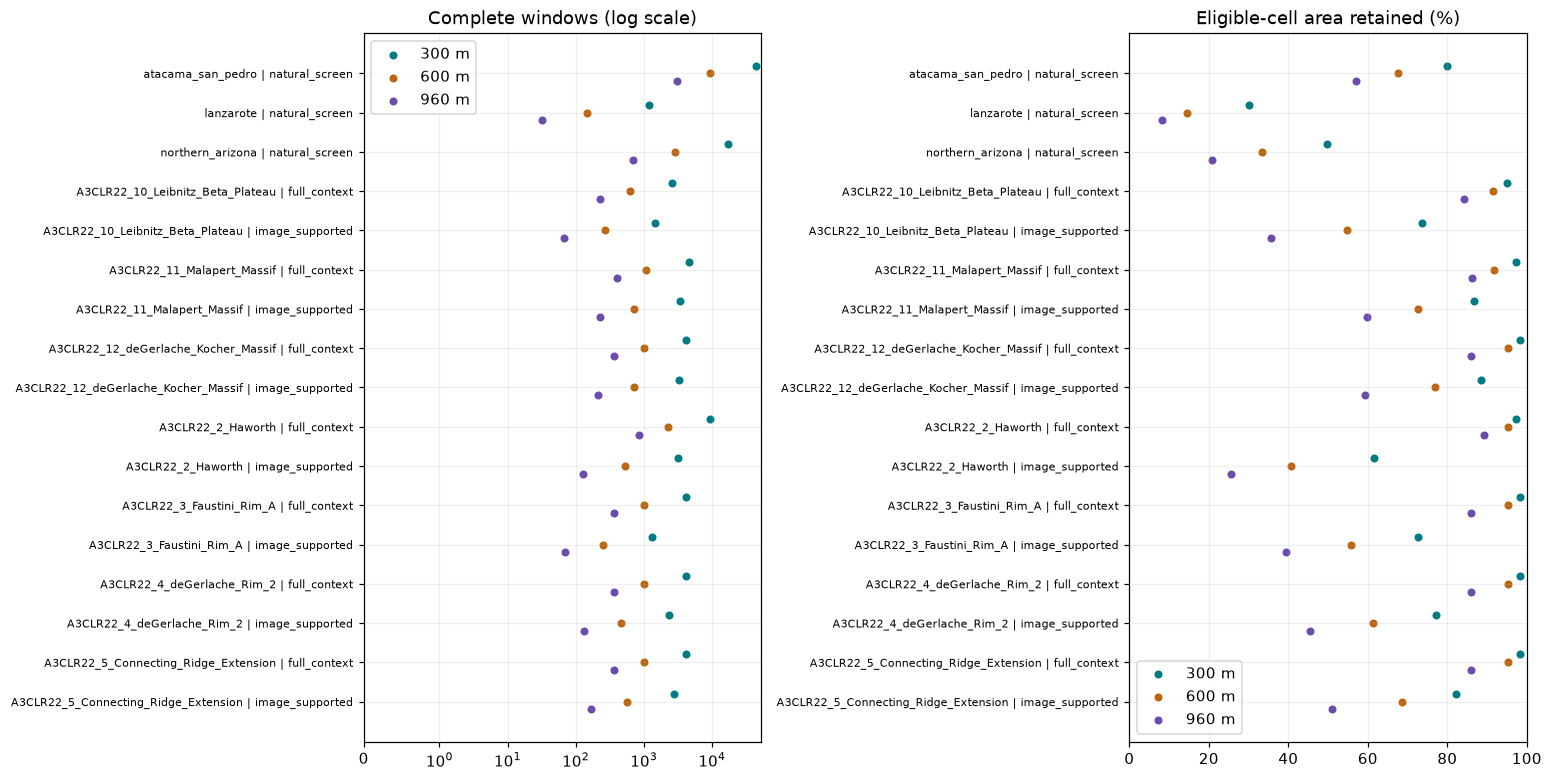

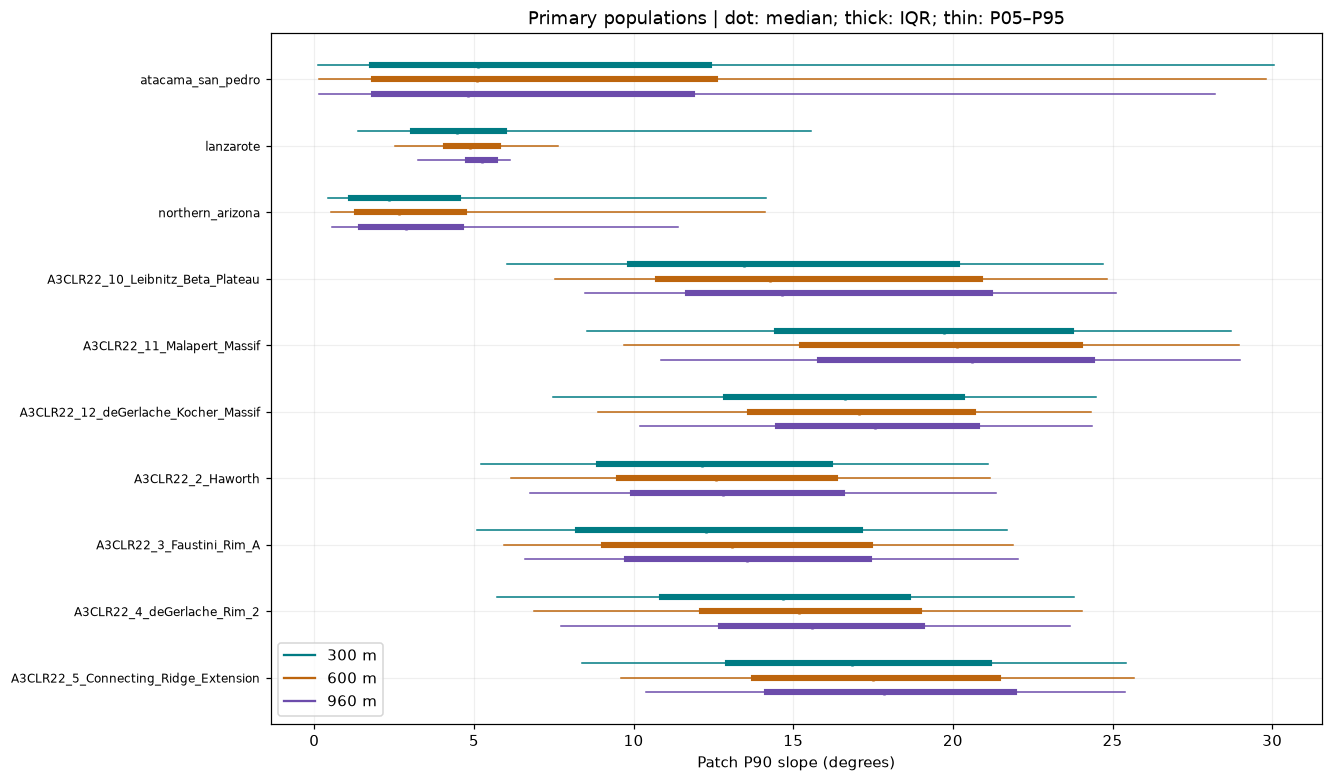

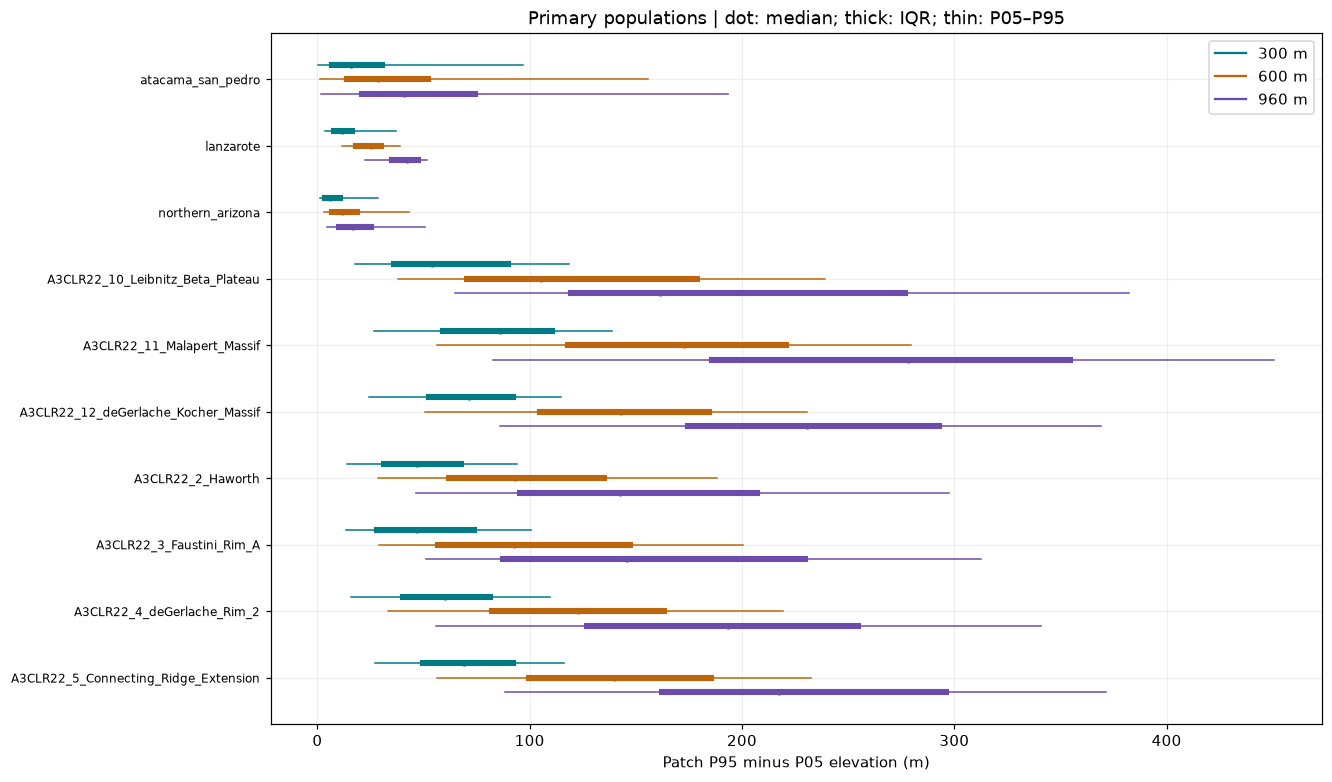

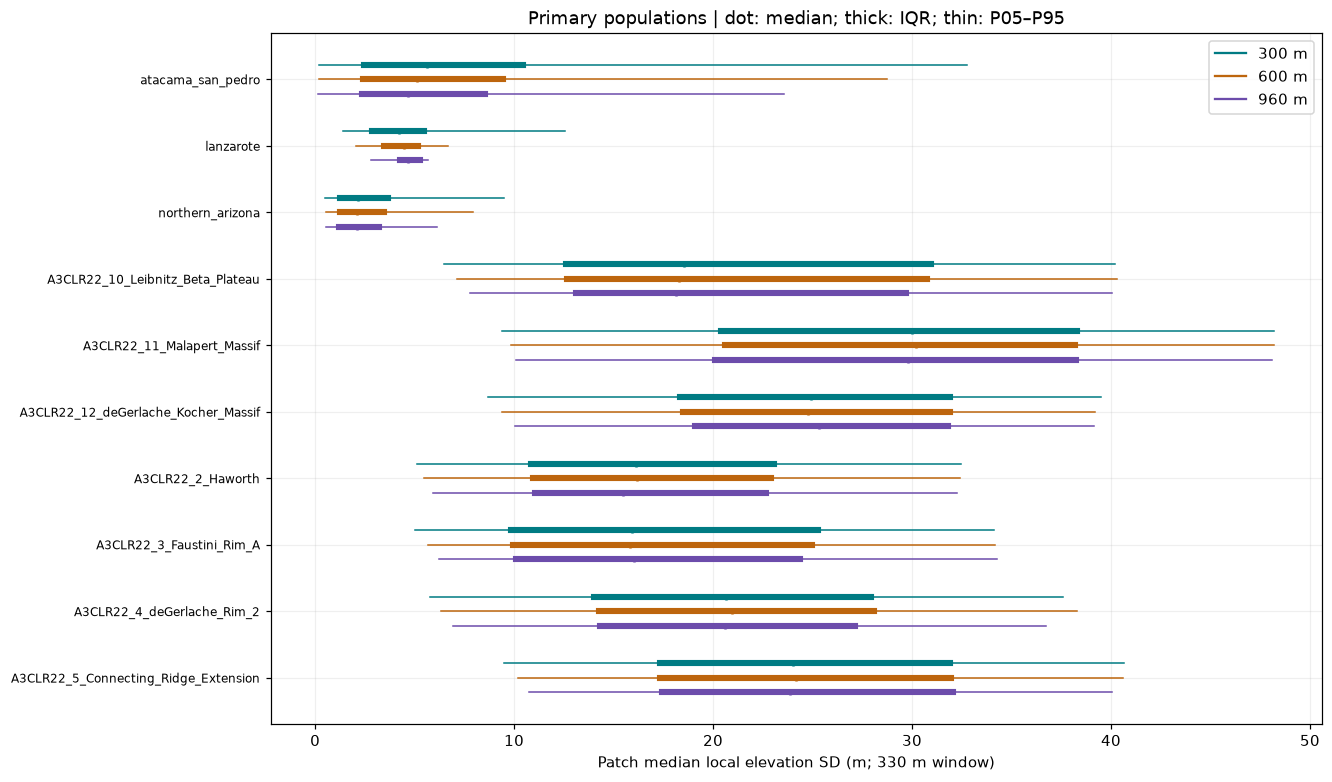

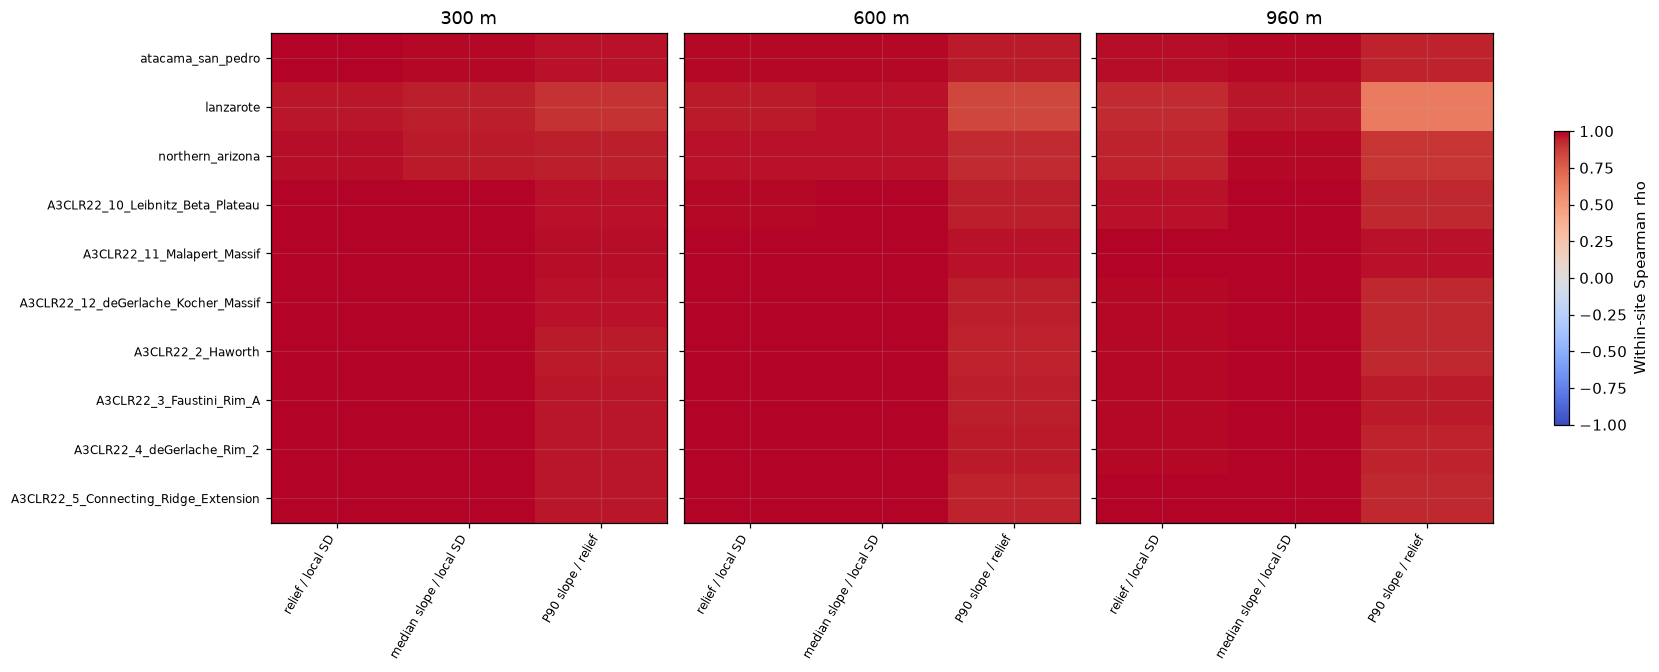

In [10]:
stat_rows: list[dict[str, Any]] = []
correlation_rows: list[dict[str, Any]] = []
for _, raw_group in patches.groupby(GROUP, sort=True):
    group = pd.DataFrame(raw_group)
    identity = {name: group.iloc[0][name] for name in GROUP}
    for feature in DESCRIPTORS:
        quantiles = np.quantile(group[feature].to_numpy(dtype=float), [.05, .25, .5, .75, .95])
        stat_rows.append({**identity, 'feature': feature, 'patches': len(group),
                          **dict(zip(['p05', 'p25', 'median', 'p75', 'p95'], map(float, quantiles), strict=True))})
    for first, second in [('slope_median_deg', 'local_sd_median_m'),
                          ('central_relief_m', 'local_sd_median_m'),
                          ('slope_p90_deg', 'central_relief_m')]:
        defined = len(group) >= 3 and group[first].nunique() > 1 and group[second].nunique() > 1
        association = pd.DataFrame(group[[first, second]]).corr(method='spearman')
        value = float(association.loc[first, second]) if defined else np.nan
        correlation_rows.append({**identity, 'first': first, 'second': second,
                                 'spearman_rho': value, 'patches': len(group), 'defined': defined})
statistics = pd.DataFrame(stat_rows)
correlations = pd.DataFrame(correlation_rows)
statistics.to_csv(OUT / 'descriptor_statistics.csv', index=False)
correlations.to_csv(OUT / 'correlations.csv', index=False)
primary = pd.DataFrame(patches.loc[patches['population'].isin(['natural_screen', 'full_context'])]).copy()
region_order = [region for _, region, _ in site_specs]
colors = {300: '#007b83', 600: '#bd650d', 960: '#6c4cab'}

fig, axes = plt.subplots(1, 2, figsize=(14, 7), layout='constrained')
labels = [f'{r["region"]} | {r["population"]}'
          for r in pd.DataFrame(inventory.loc[inventory['size_m'] == 300]).to_dict('records')]
for ax, column, title in zip(axes, ['complete_windows', 'retained_pct_of_eligible_cells'],
                            ['Complete windows (log scale)', 'Eligible-cell area retained (%)'], strict=True):
    for offset, size_m in enumerate(SIZES_M):
        rows = inventory[inventory['size_m'] == size_m]
        ax.scatter(rows[column], np.arange(len(rows)) + (offset - 1) * .2,
                   color=colors[size_m], label=f'{size_m} m', s=18)
    ax.set_yticks(range(len(labels)), labels, fontsize=7)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.legend()
axes[0].set_xscale('symlog', linthresh=1)
axes[0].set_xlim(0, float(inventory['complete_windows'].max()) * 1.2)
axes[1].set_xlim(0, 100)
save_figure(fig, 'patch_availability')

for feature in ['slope_p90_deg', 'central_relief_m', 'local_sd_median_m']:
    fig, ax = plt.subplots(figsize=(12, 7), layout='constrained')
    for offset, size_m in enumerate(SIZES_M):
        for position, region in enumerate(region_order):
            rows = statistics[(statistics['region'] == region) & (statistics['size_m'] == size_m)
                              & (statistics['feature'] == feature)
                              & statistics['population'].isin(['natural_screen', 'full_context'])]
            if rows.empty:
                continue
            record = rows.iloc[0]
            y = position + (offset - 1) * .22
            ax.plot([record['p05'], record['p95']], [y, y], color=colors[size_m], linewidth=1)
            ax.plot([record['p25'], record['p75']], [y, y], color=colors[size_m], linewidth=4)
            ax.plot(record['median'], y, 'o', color=colors[size_m], markersize=3)
        ax.plot([], [], color=colors[size_m], label=f'{size_m} m')
    ax.set_yticks(range(len(region_order)), region_order, fontsize=8)
    ax.invert_yaxis()
    ax.set(xlabel=DESCRIPTORS[feature], title='Primary populations | dot: median; thick: IQR; thin: P05–P95')
    ax.legend()
    save_figure(fig, f'distribution_{feature}')

fig, axes = plt.subplots(1, 3, figsize=(15, 6), layout='constrained', sharey=True)
plot = None
for ax, size_m in zip(axes, SIZES_M, strict=True):
    selected = correlations[(correlations['size_m'] == size_m)
                            & correlations['population'].isin(['natural_screen', 'full_context'])].copy()
    selected['pair'] = selected['first'] + ' / ' + selected['second']
    matrix = selected.pivot(index='region', columns='pair', values='spearman_rho').reindex(region_order)
    plot = ax.imshow(matrix.to_numpy(dtype=float), vmin=-1, vmax=1, cmap='coolwarm', aspect='auto')
    ax.set_xticks(range(len(matrix.columns)), ['relief / local SD', 'median slope / local SD', 'P90 slope / relief'],
                  rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(region_order)), region_order, fontsize=8)
    ax.set_title(f'{size_m} m')
assert plot is not None
fig.colorbar(plot, ax=list(axes), label='Within-site Spearman rho', shrink=.6)
save_figure(fig, 'descriptor_correlations')

# Lunar support sensitivity on the same window lattice

A shared patch has exactly the same row/column footprint in both views and all
required features in each. Count ratios do not assume that strict windows form
an exact subset. Separate full-population selection from paired metric changes.

In [11]:
sensitivity_rows: list[dict[str, Any]] = []
for region in [r for body, r, _ in site_specs if body == 'moon']:
    for size_m in SIZES_M:
        selected = pd.DataFrame(patches.loc[(patches['region'] == region) & (patches['size_m'] == size_m)])
        full = pd.DataFrame(selected.loc[selected['population'] == 'full_context'])
        strict = pd.DataFrame(selected.loc[selected['population'] == 'image_supported'])
        paired = full.merge(strict, on=['row', 'col'], suffixes=('_full', '_strict'), validate='one_to_one')
        for feature in DESCRIPTORS:
            delta = paired[f'{feature}_full'].to_numpy(dtype=float) - paired[f'{feature}_strict'].to_numpy(dtype=float)
            full_median = float(full[feature].median()) if len(full) else np.nan
            shared_median = float(paired[f'{feature}_full'].median()) if len(paired) else np.nan
            sensitivity_rows.append({
                'region': region, 'size_m': size_m, 'feature': feature,
                'full_patches': len(full), 'strict_patches': len(strict), 'shared_patches': len(paired),
                'strict_only_patches': len(strict) - len(paired),
                'strict_full_count_ratio_pct': 100 * len(strict) / len(full) if len(full) else np.nan,
                'full_all_median': full_median, 'full_shared_median': shared_median,
                'full_all_minus_shared_median': full_median - shared_median,
                'paired_median_delta': float(np.median(delta)) if len(delta) else np.nan,
                'paired_max_abs_delta': float(np.max(np.abs(delta))) if len(delta) else np.nan,
            })
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.to_csv(OUT / 'lunar_sensitivity.csv', index=False)
display(sensitivity[sensitivity['feature'] == 'slope_p90_deg'])
display(origins[(origins['region'] == 'lanzarote') & (origins['size_m'] == 960)])

,region,size_m,feature,full_patches,strict_patches,shared_patches,strict_only_patches,strict_full_count_ratio_pct,full_all_median,full_shared_median,full_all_minus_shared_median,paired_median_delta,paired_max_abs_delta
1,A3CLR22_10_Leibnitz_Beta_Plateau,300,slope_p90_deg,2601,1443,1443,0,55.478662,13.449467,18.154995,-4.705528,0.0,0.0
6,A3CLR22_10_Leibnitz_Beta_Plateau,600,slope_p90_deg,625,268,268,0,42.880000,14.261178,21.606476,-7.345298,0.0,0.0
11,A3CLR22_10_Leibnitz_Beta_Plateau,960,slope_p90_deg,225,68,68,0,30.222222,14.636209,22.964249,-8.328040,0.0,0.0
16,A3CLR22_11_Malapert_Massif,300,slope_p90_deg,4624,3404,3404,0,73.615917,19.707039,21.941216,-2.234177,0.0,0.0
21,A3CLR22_11_Malapert_Massif,600,slope_p90_deg,1089,713,713,0,65.472911,20.137037,22.809359,-2.672322,0.0,0.0
26,A3CLR22_11_Malapert_Massif,960,slope_p90_deg,400,229,229,0,57.250000,20.593670,23.768697,-3.175027,0.0,0.0
31,A3CLR22_12_deGerlache_Kocher_Massif,300,slope_p90_deg,4225,3294,3294,0,77.964497,16.612097,17.559304,-0.947207,0.0,0.0
36,A3CLR22_12_deGerlache_Kocher_Massif,600,slope_p90_deg,1024,715,715,0,69.824219,17.057667,18.346158,-1.288490,0.0,0.0
41,A3CLR22_12_deGerlache_Kocher_Massif,960,slope_p90_deg,361,216,216,0,59.833795,17.554840,19.350914,-1.796074,0.0,0.0
46,A3CLR22_2_Haworth,300,slope_p90_deg,9409,3188,3188,0,33.882453,12.129240,16.879575,-4.750335,0.0,0.0


,body,region,population,size_m,origin_row,origin_col,stride_cells,complete_windows,retained_pct_of_eligible_cells
20,earth,lanzarote,natural_screen,960,0,0,32,32,8.131038
21,earth,lanzarote,natural_screen,960,0,16,32,30,7.622848
22,earth,lanzarote,natural_screen,960,16,0,32,29,7.368753
23,earth,lanzarote,natural_screen,960,16,16,32,30,7.622848


# Representative patches: low, median and high P90 slope

For each primary site and size, select the actual patch nearest the site's P05,
median and P95 of patch P90 slope (ties by row then column). These are slope-based
examples, not representative of every landform. All selected coordinates are saved.
Elevation colors are centered on each patch's mean; one symmetric color range is
shared across all displayed sites and sizes. Slope colors span 0–90 degrees.
Hatching marks cells outside the strict lunar complete-feature mask; it is not
a direct map of image counts. Larger panels span larger physical extents.

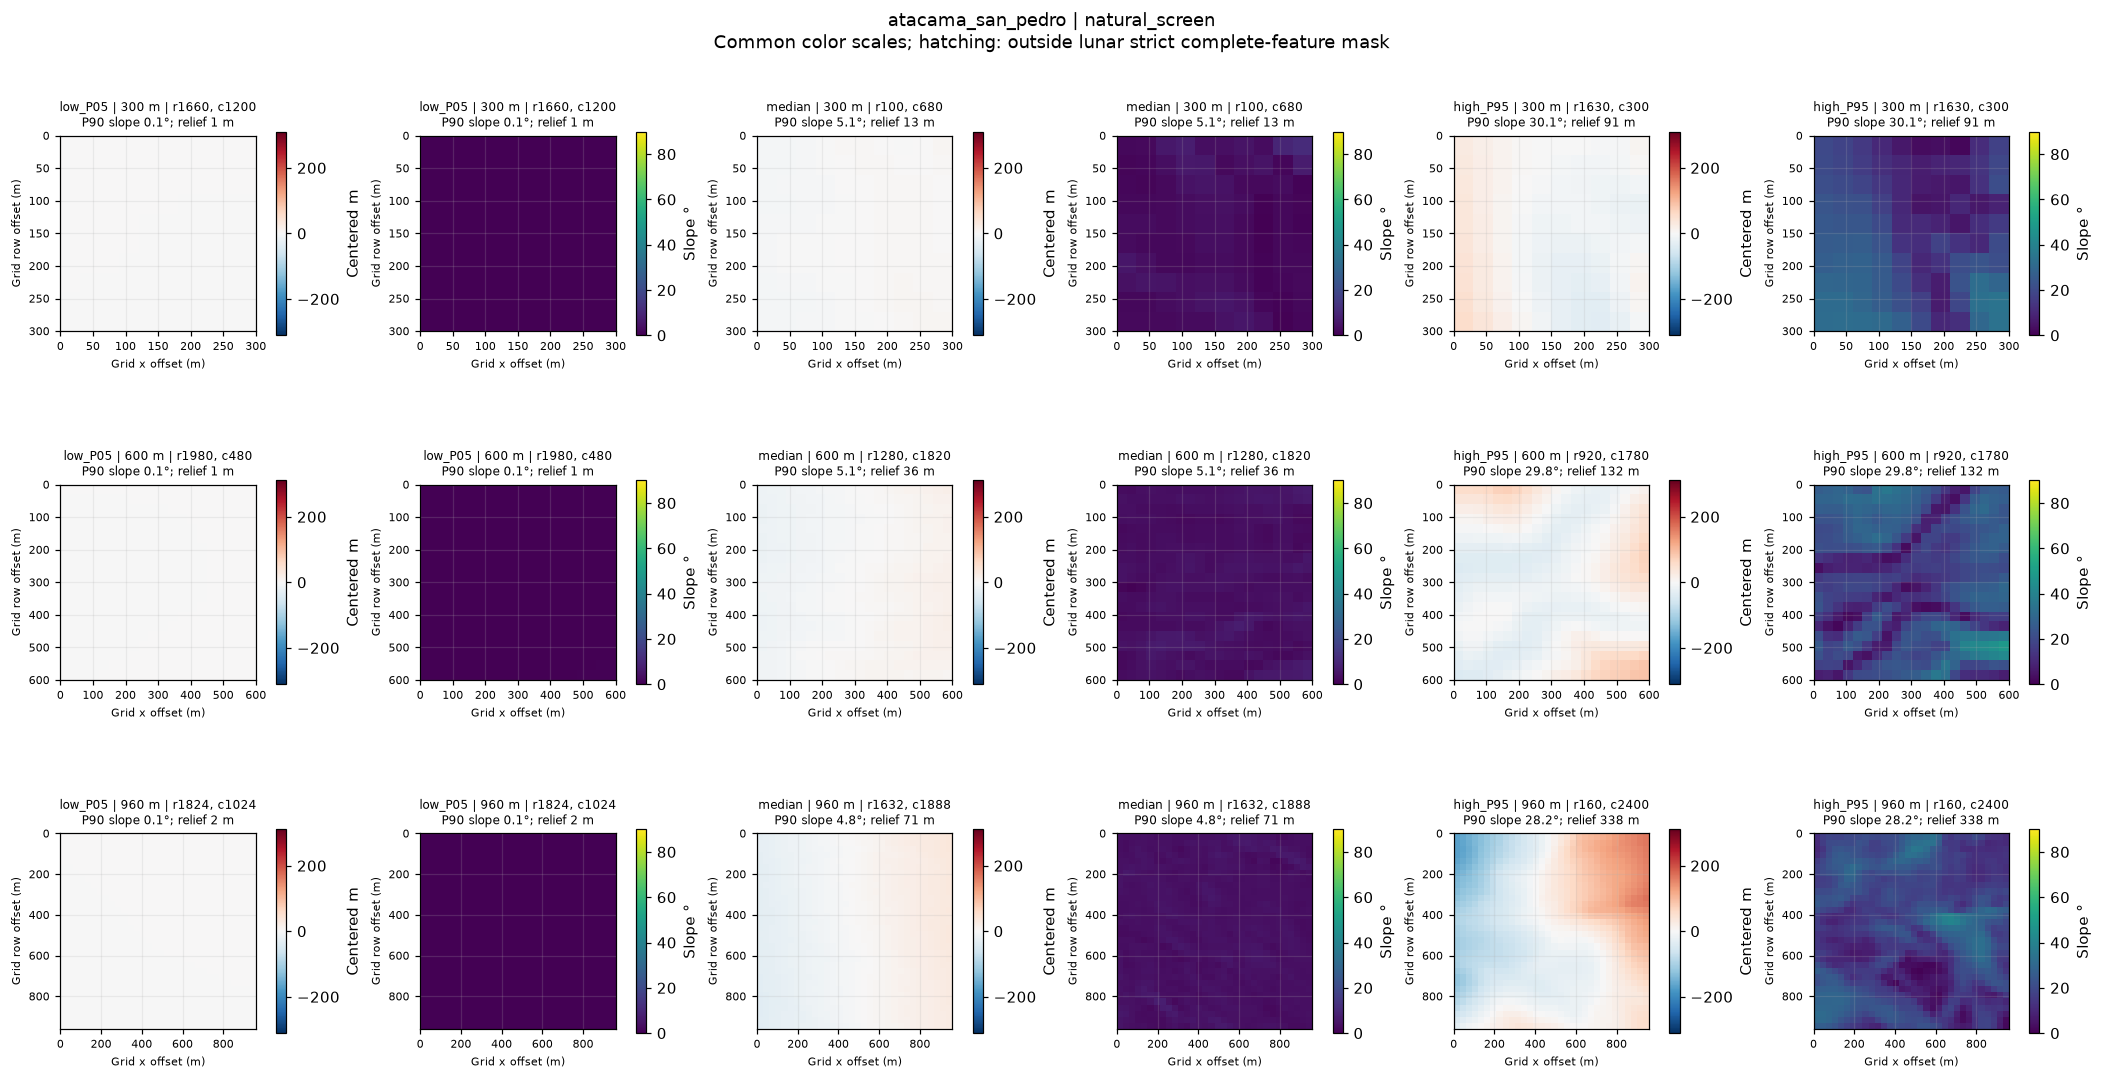

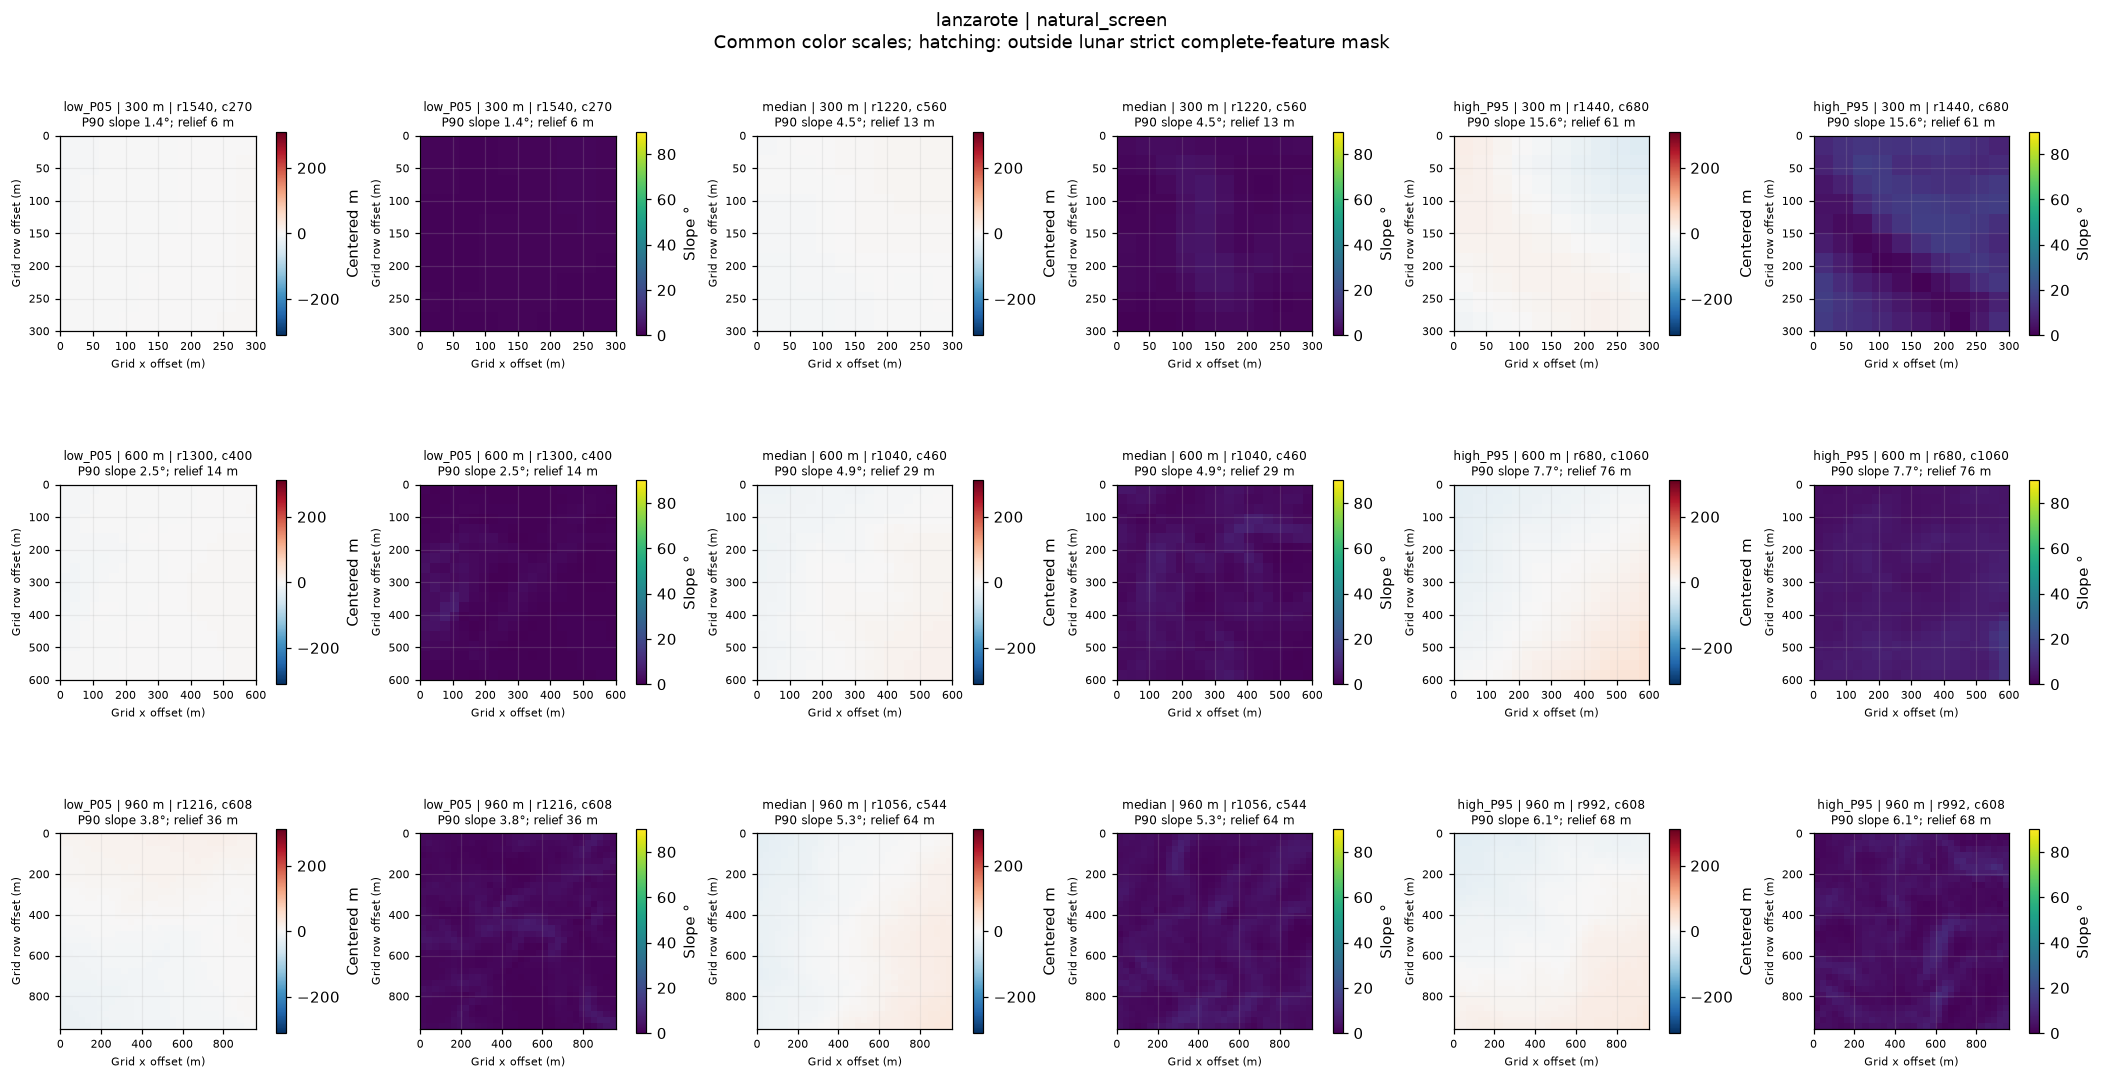

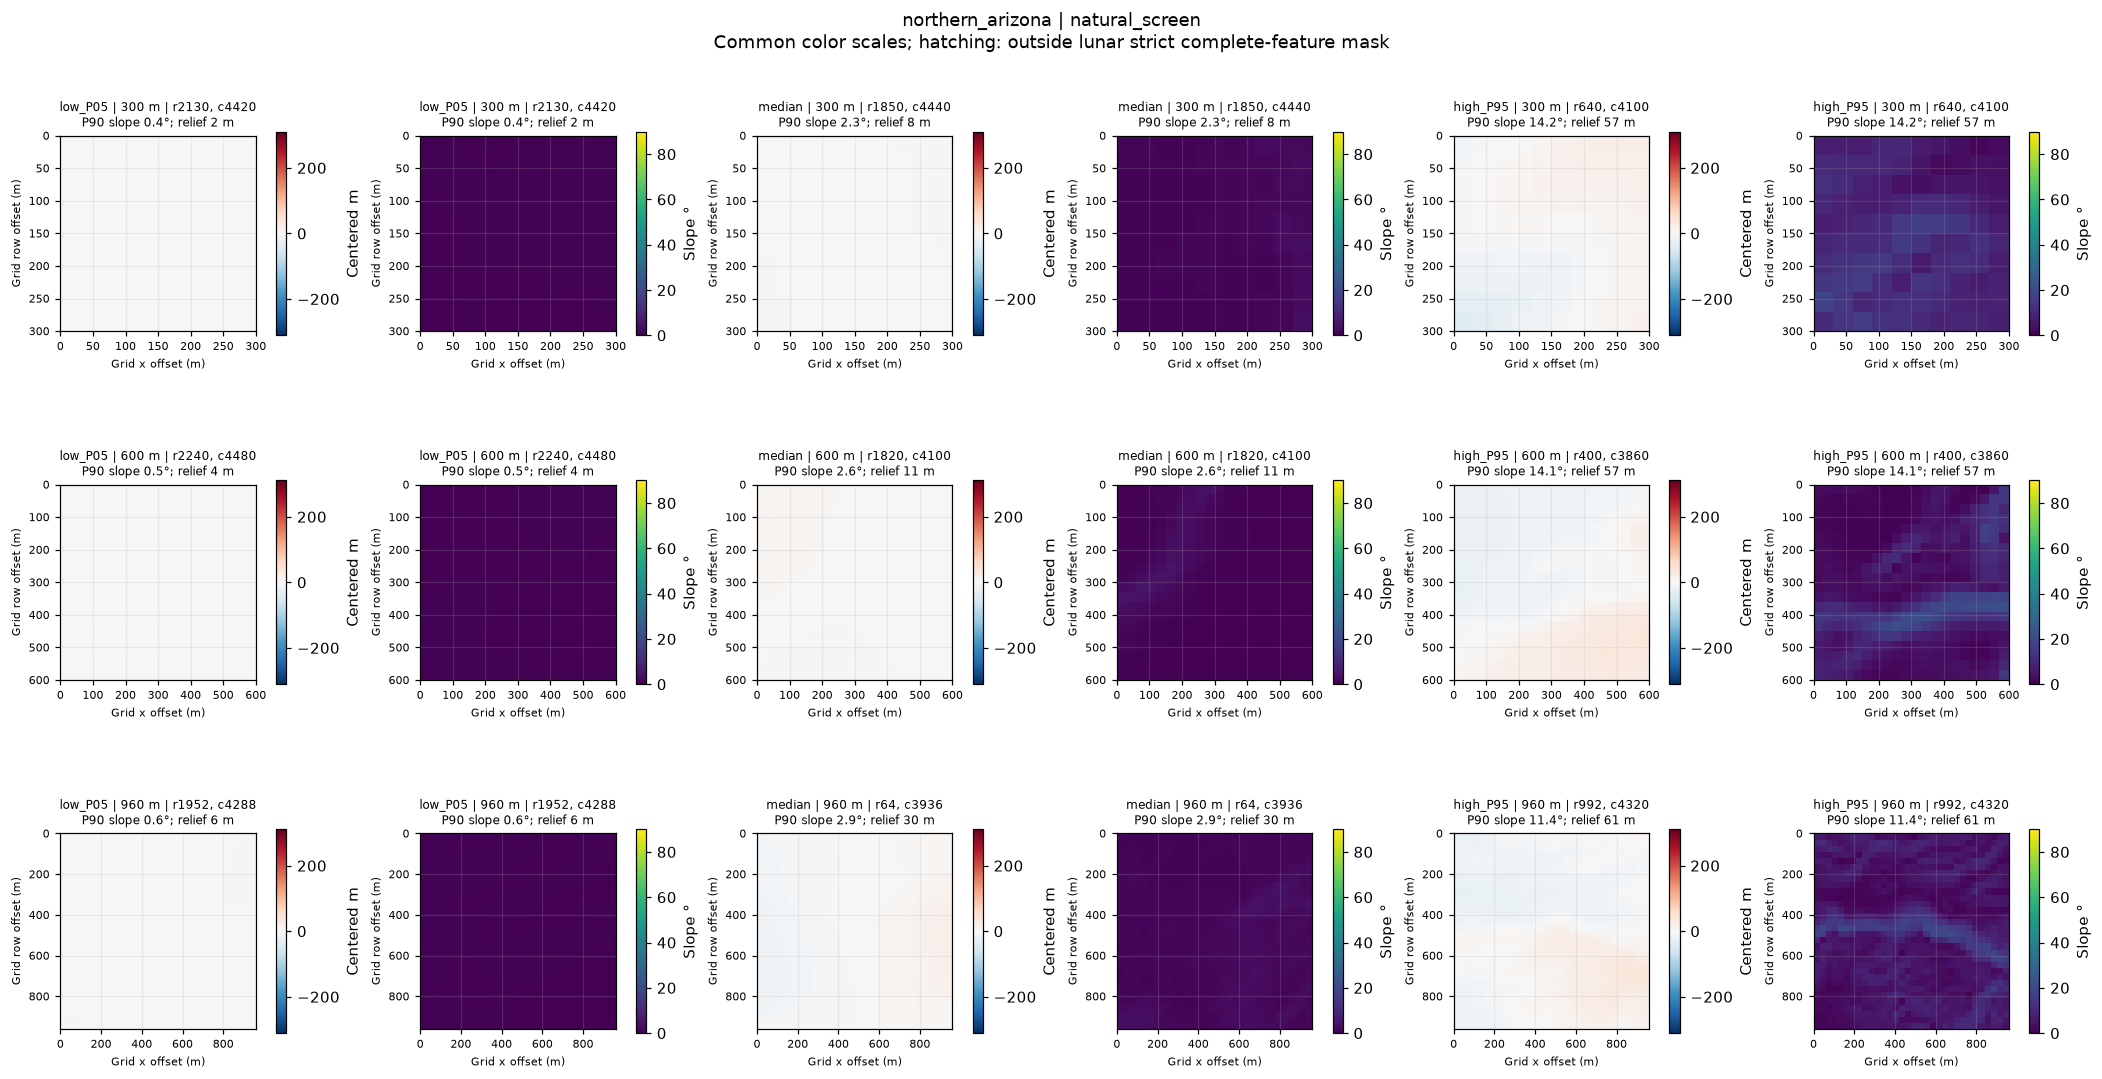

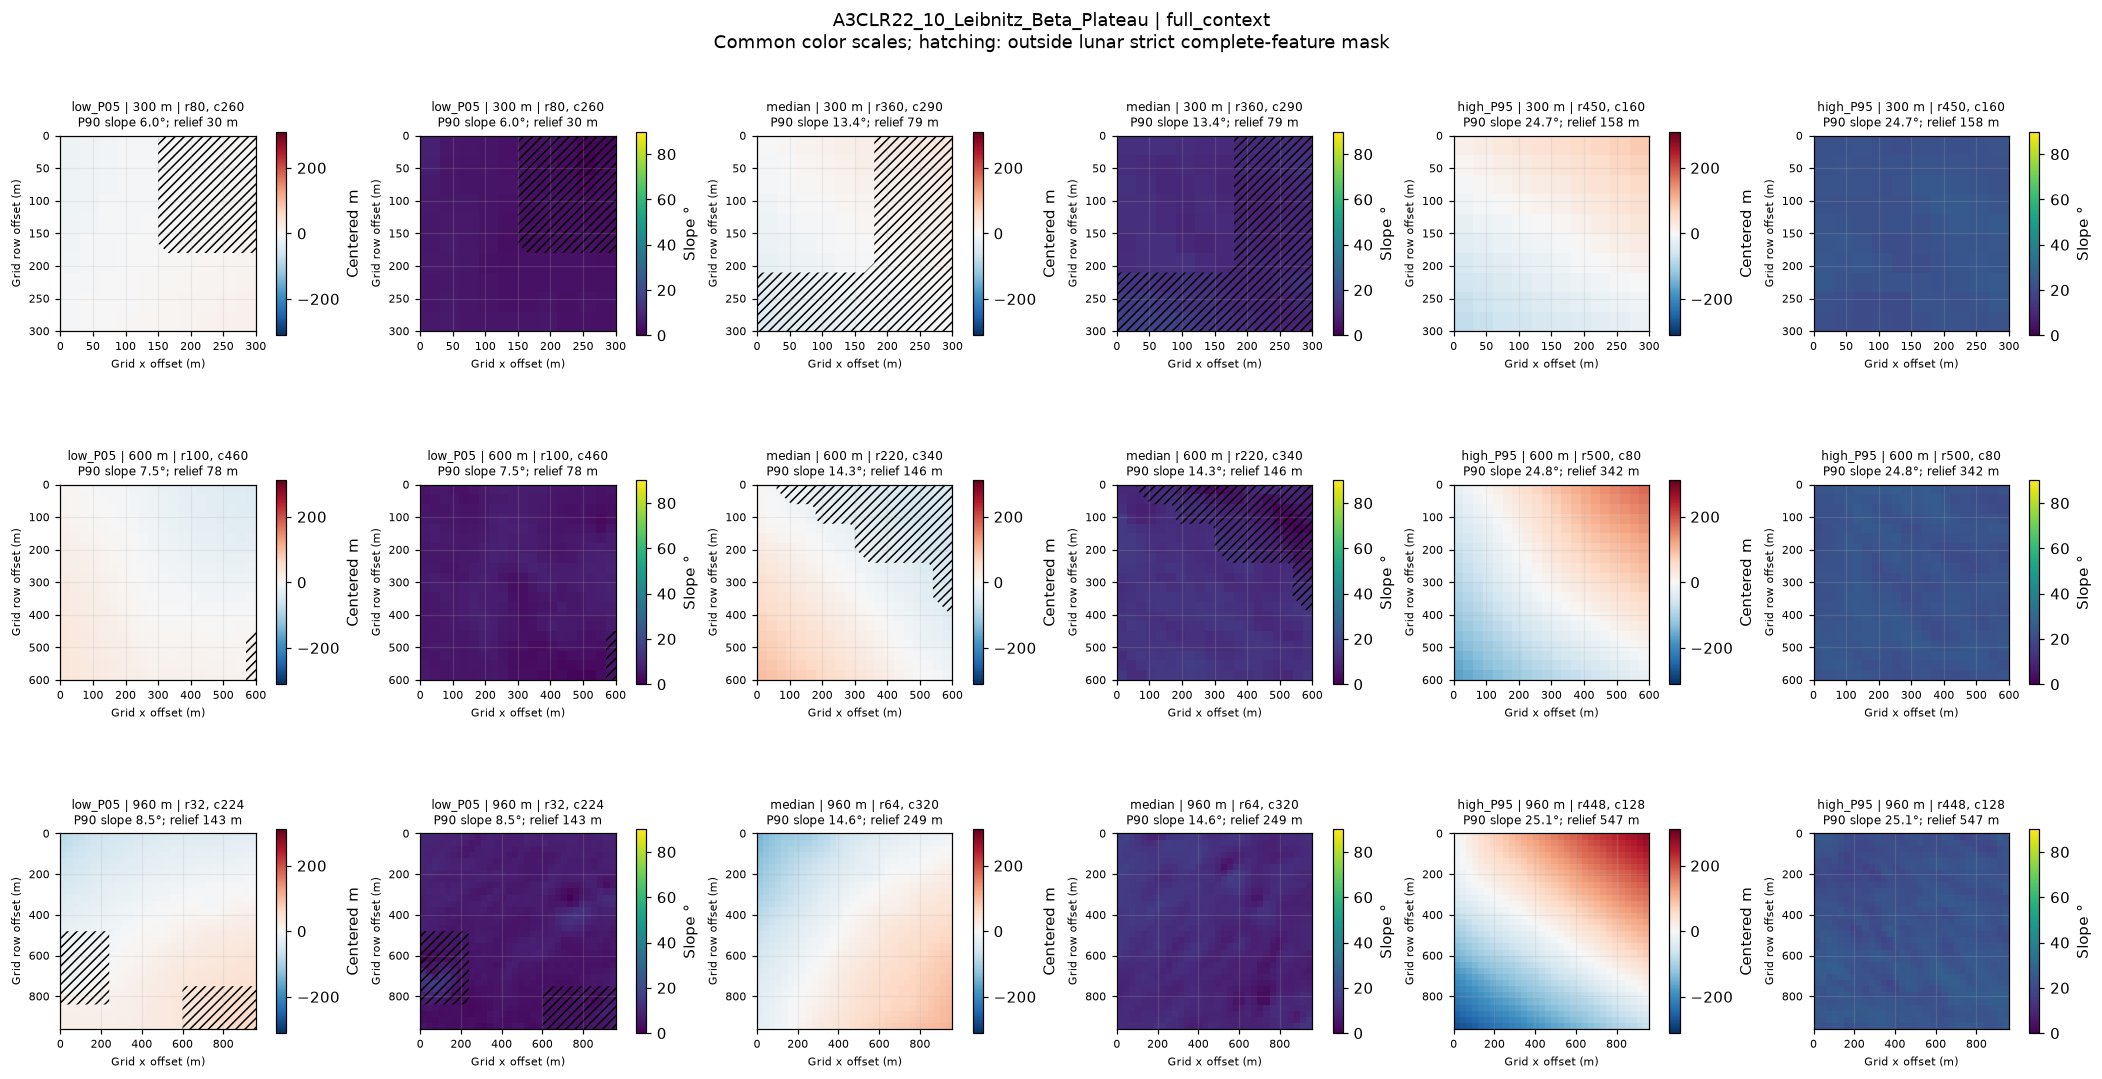

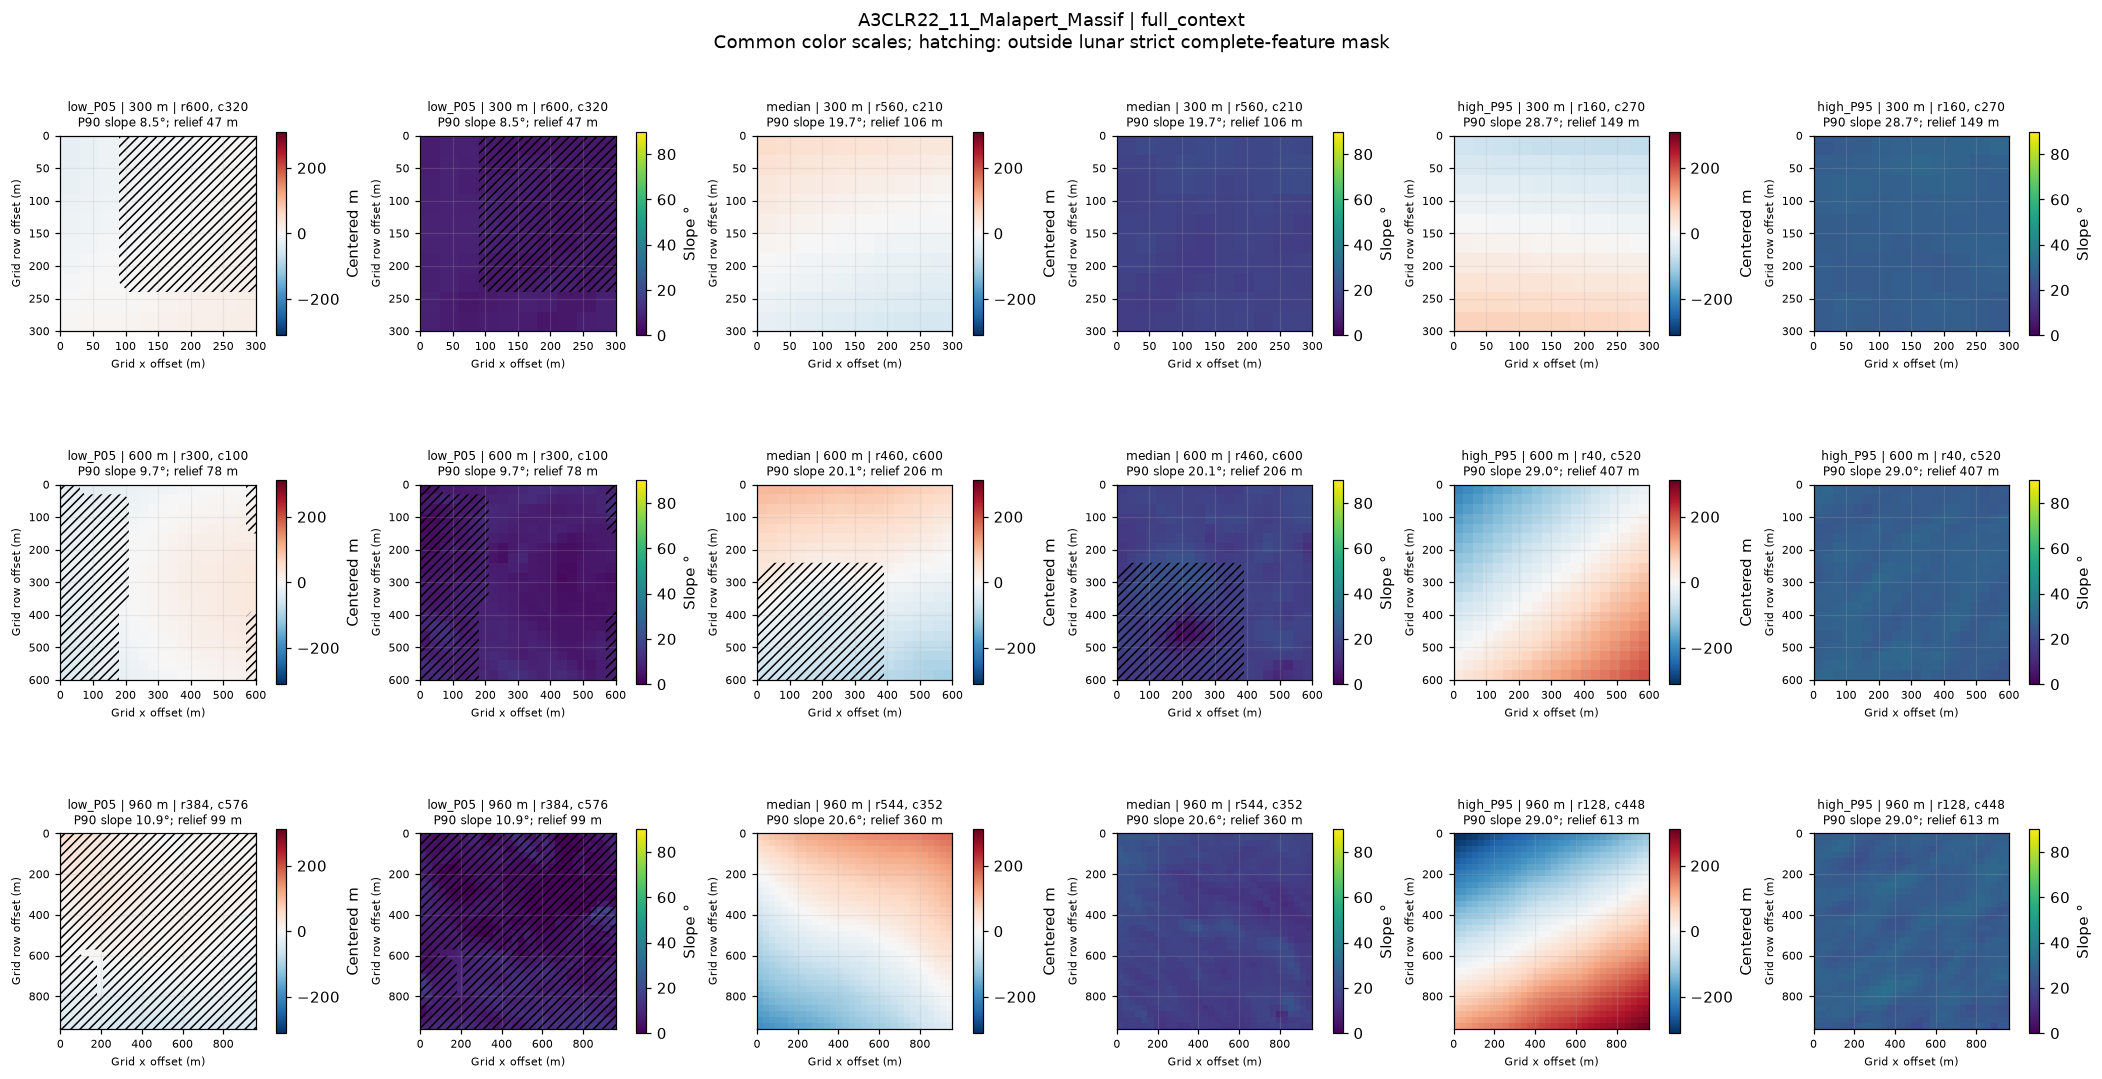

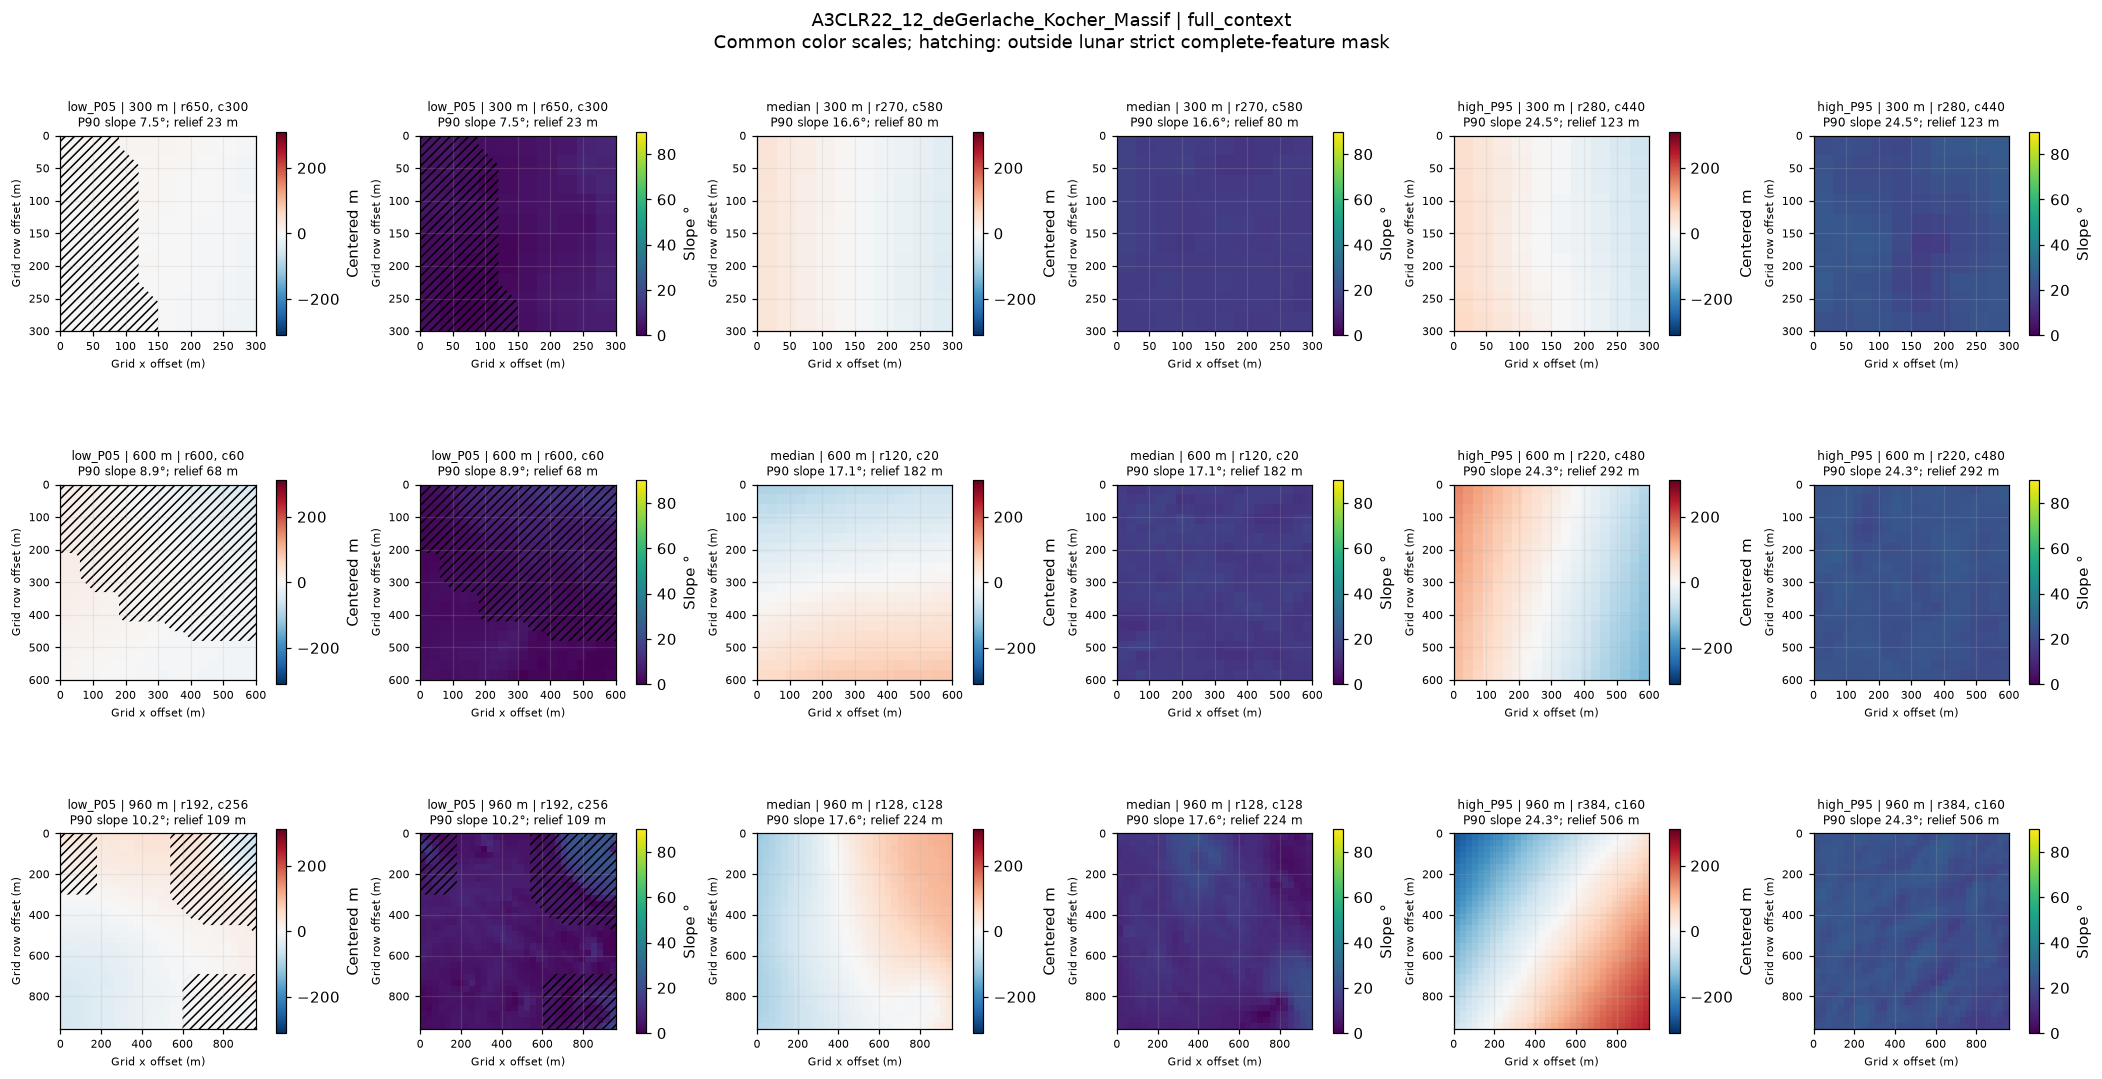

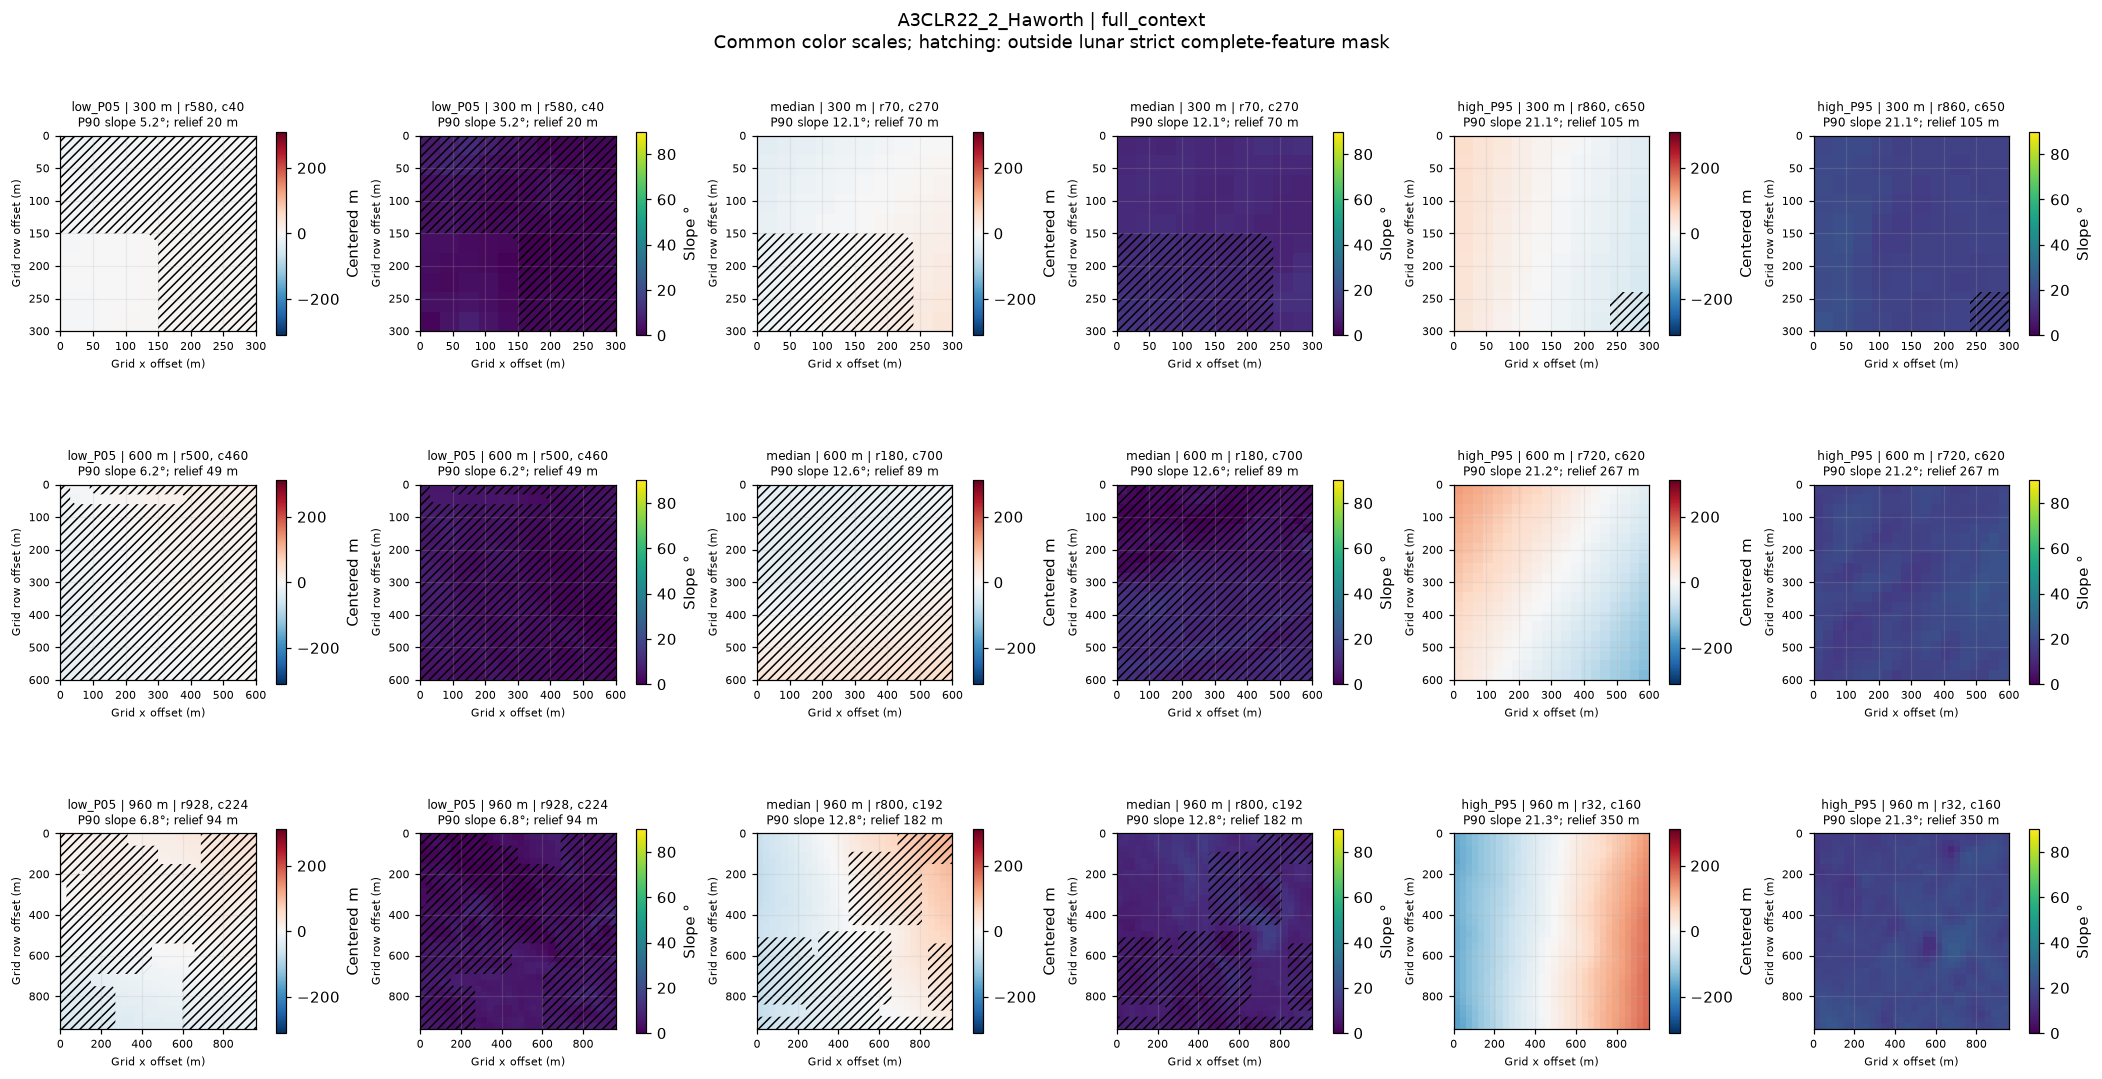

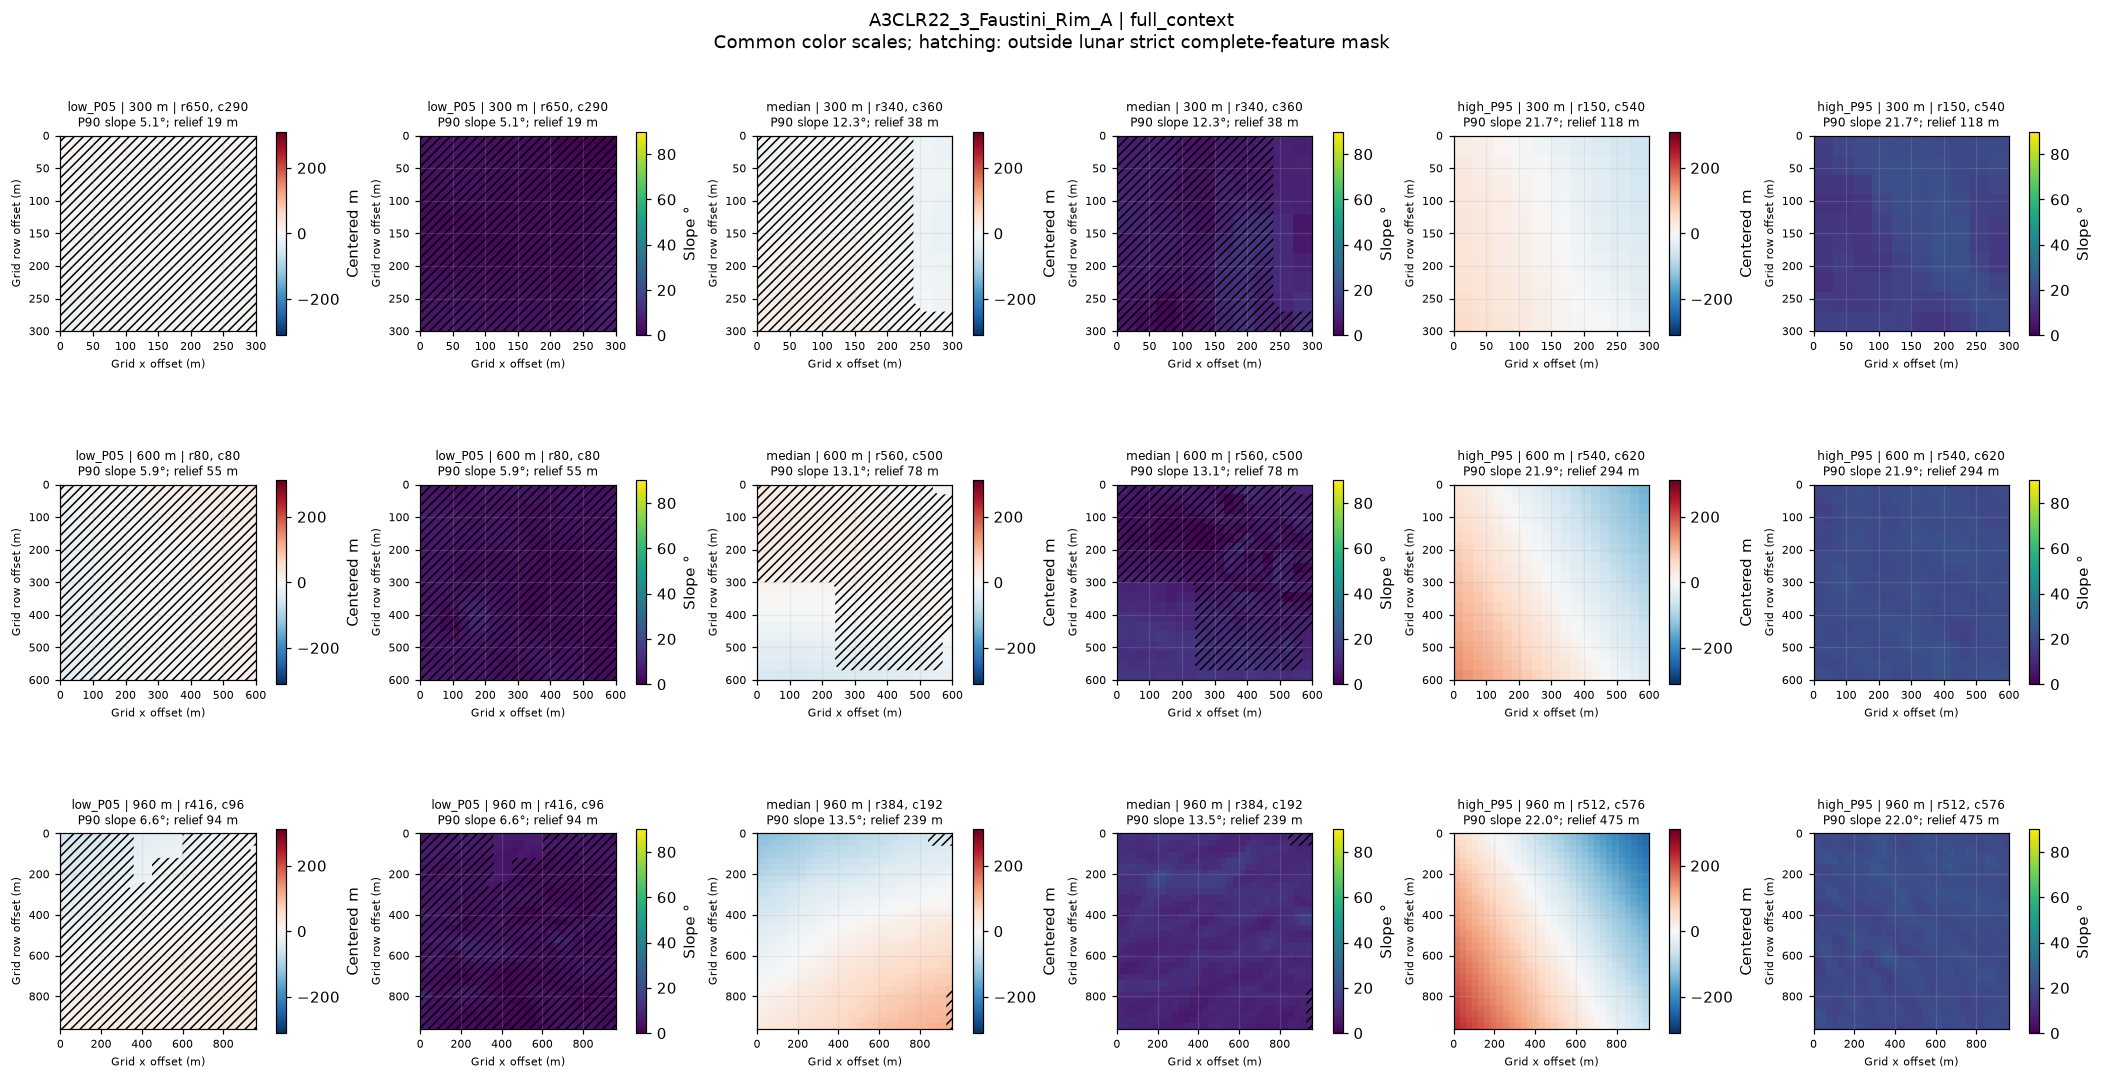

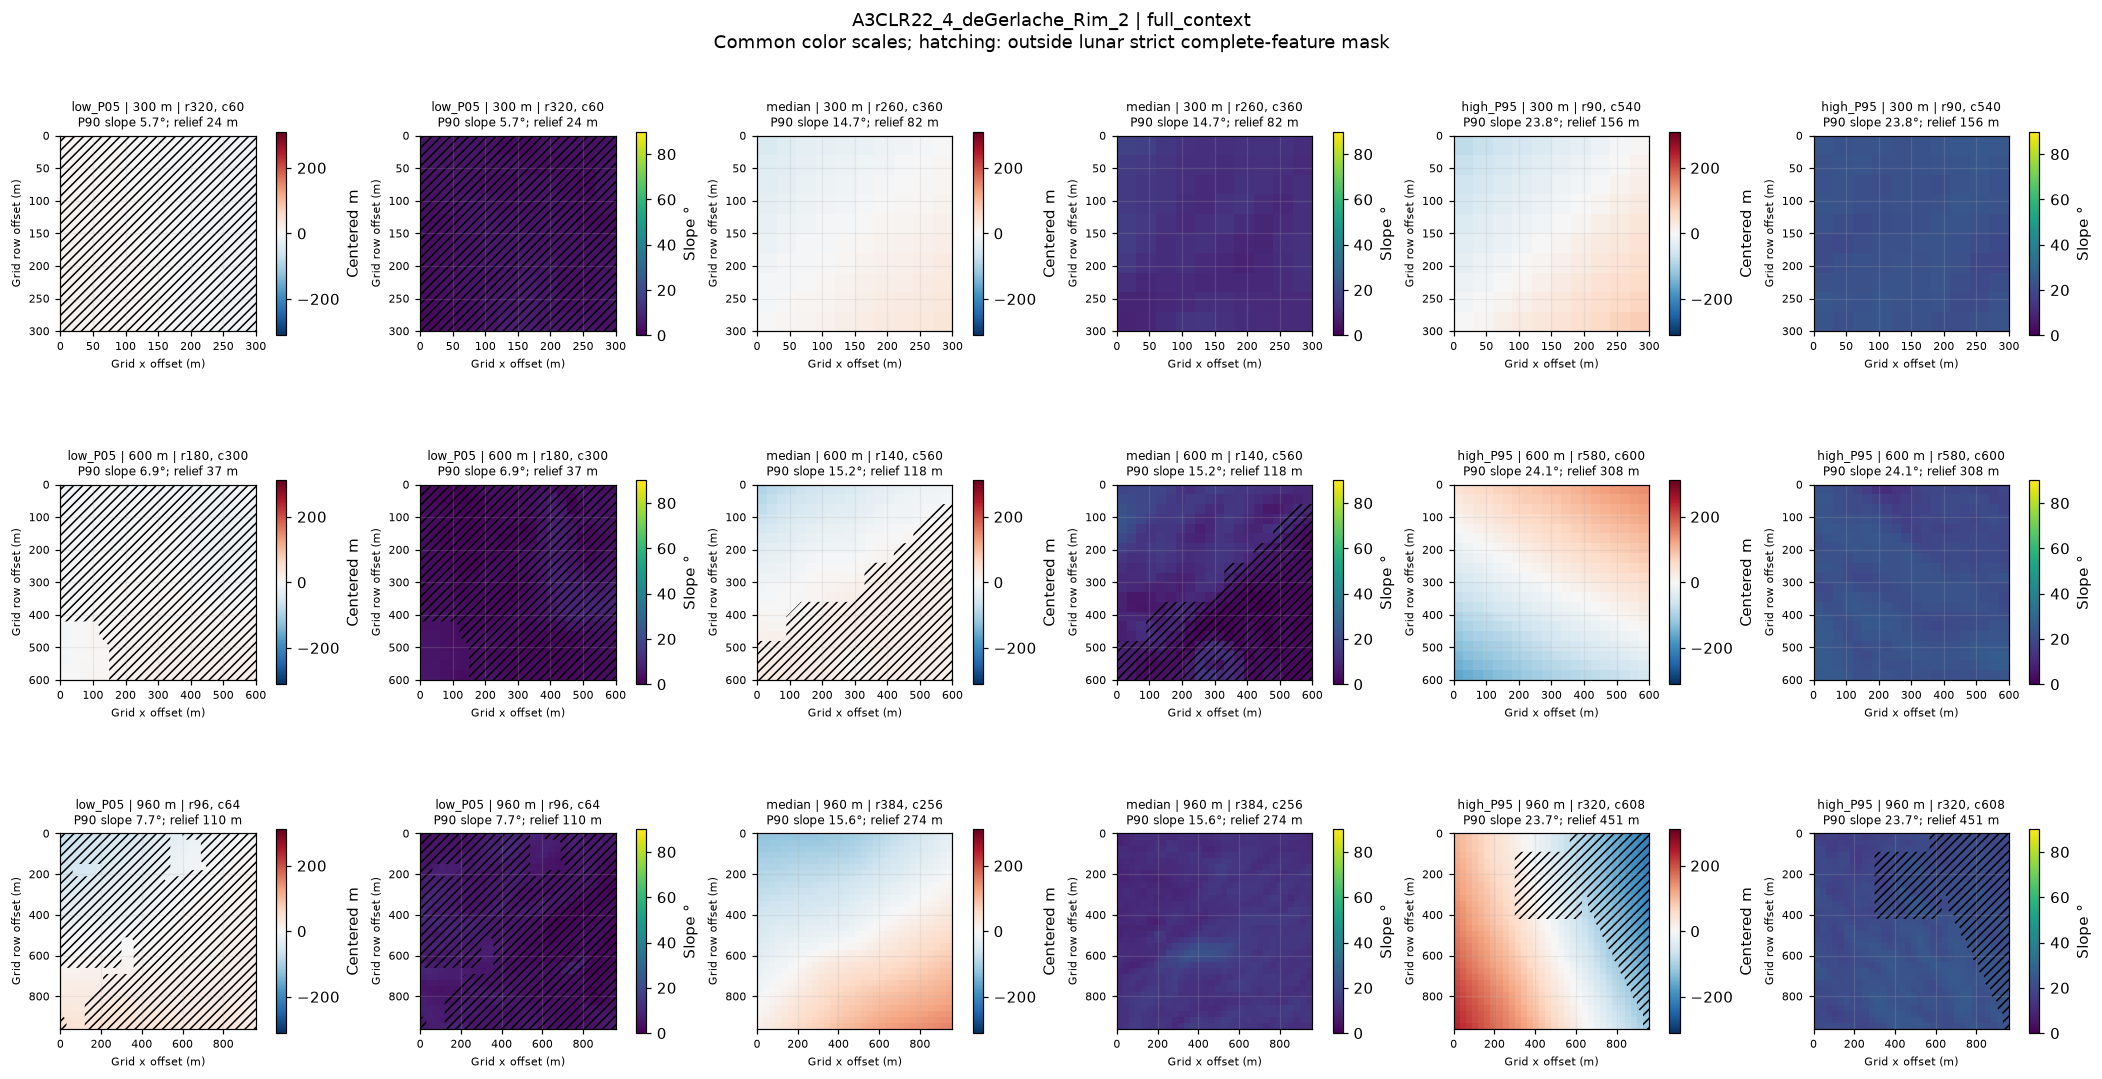

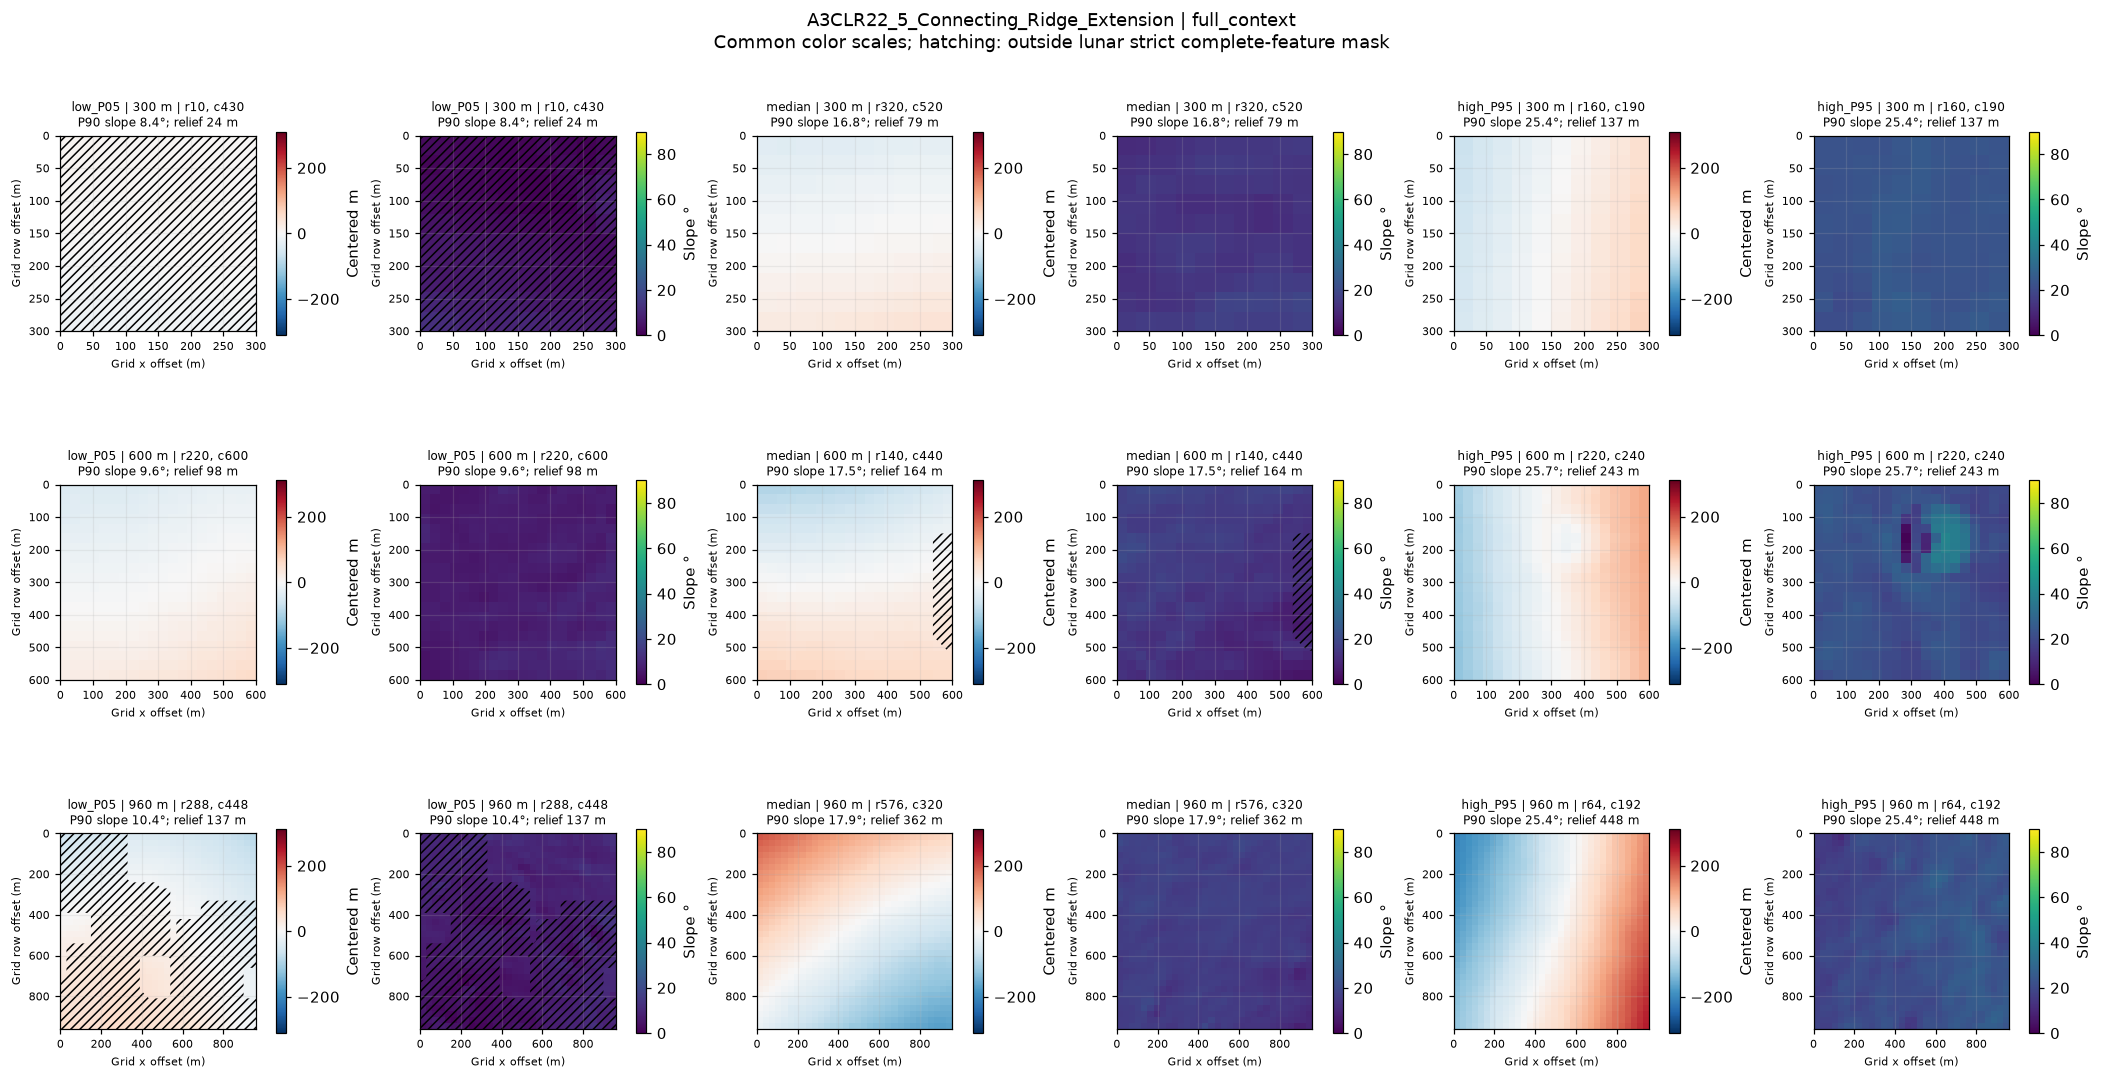

In [12]:
gallery_rows: list[dict[str, Any]] = []
gallery_data: dict[str, tuple[np.ndarray, np.ndarray, np.ndarray]] = {}
for _, raw_group in primary.groupby(GROUP, sort=True):
    ordered = pd.DataFrame(raw_group).sort_values(['row', 'col'])
    for label, probability in [('low_P05', .05), ('median', .5), ('high_P95', .95)]:
        target = float(np.quantile(ordered['slope_p90_deg'].to_numpy(dtype=float), probability))
        position = int(np.argmin(np.abs(ordered['slope_p90_deg'].to_numpy(dtype=float) - target)))
        example = ordered.to_dict('records')[position]
        example['selection'] = label
        example['target_patch_p90_slope_deg'] = target
        gallery_rows.append(example)
        window = Window.from_slices(
            (int(example['row']), int(example['row'] + example['side_cells'])),
            (int(example['col']), int(example['col'] + example['side_cells'])))
        folder = layer_folders[example['region'], example['population']]
        with rasterio.open(check_input(folder / 'elevation_m.tif', expected, evidence)) as dataset:
            elevation = dataset.read(1, window=window).astype(float)
        with rasterio.open(check_input(folder / 'slope_deg.tif', expected, evidence)) as dataset:
            slope = dataset.read(1, window=window).astype(float)
        unsupported = np.zeros(elevation.shape, dtype=bool)
        if example['body'] == 'moon':
            with rasterio.open(check_input(strict_mask_paths[example['region']], expected, evidence)) as dataset:
                unsupported = dataset.read(1, window=window) != 1
        centered = elevation - elevation.mean()
        gallery_data[example['patch_id']] = (centered, slope, unsupported)
gallery = pd.DataFrame(gallery_rows)
gallery.to_csv(OUT / 'gallery_patches.csv', index=False)
elevation_limit = max(float(np.max(np.abs(z))) for z, _, _ in gallery_data.values())
provenance['gallery_elevation_symmetric_limit_m'] = elevation_limit
for body, region, _ in site_specs:
    fig, axes = plt.subplots(3, 6, figsize=(19, 10), layout='constrained')
    for size_index, size_m in enumerate(SIZES_M):
        for selection_index, label in enumerate(['low_P05', 'median', 'high_P95']):
            records = gallery[(gallery['region'] == region) & (gallery['size_m'] == size_m)
                              & (gallery['selection'] == label)]
            for feature_index in range(2):
                ax = axes[size_index, selection_index * 2 + feature_index]
                if records.empty:
                    ax.text(.5, .5, 'No eligible patches', ha='center', transform=ax.transAxes)
                    ax.set_axis_off()
                    continue
                record = records.iloc[0]
                elevation, slope, unsupported = gallery_data[str(record['patch_id'])]
                values = elevation if feature_index == 0 else slope
                plot = ax.imshow(values, extent=(0, size_m, size_m, 0), interpolation='nearest',
                                 cmap='RdBu_r' if feature_index == 0 else 'viridis',
                                 vmin=-elevation_limit if feature_index == 0 else 0,
                                 vmax=elevation_limit if feature_index == 0 else 90)
                if unsupported.any():
                    centers = (np.arange(-1, values.shape[0] + 1) + .5) * SPACING_M
                    ax.contourf(centers, centers, np.pad(unsupported, 1, mode='edge').astype(float), levels=[.5, 1.5],
                                colors='none', hatches=['////'])
                    ax.set_xlim(0, size_m)
                    ax.set_ylim(size_m, 0)
                ax.set_title(f'{label} | {size_m} m | r{record["row"]}, c{record["col"]}\n'
                             f'P90 slope {record["slope_p90_deg"]:.1f}°; relief {record["relief_m"]:.0f} m', fontsize=8)
                ax.set_xlabel('Grid x offset (m)', fontsize=7)
                ax.set_ylabel('Grid row offset (m)', fontsize=7)
                ax.tick_params(labelsize=7)
                fig.colorbar(plot, ax=ax, shrink=.6, label='Centered m' if feature_index == 0 else 'Slope °')
    fig.suptitle(f'{region} | {"natural_screen" if body == "earth" else "full_context"}\n'
                 'Common color scales; hatching: outside lunar strict complete-feature mask')
    save_figure(fig, f'gallery_{region}')

# Findings and next questions

The report separates availability, selection effects and descriptive feature
associations. No p-values or independence-based confidence intervals are used.
The first-cycle findings will determine the next branch of the living EDA plan.

In [13]:
# Read the Markdown notes below for the standalone report export.
report_notebook = json.loads((ROOT / 'notebooks/exploration/15_patch_terrain_eda.ipynb').read_text(encoding="utf-8"))
report_notes = {entry["metadata"]["report_section"]: "".join(entry["source"])
                for entry in report_notebook["cells"]
                if entry["cell_type"] == "markdown" and "report_section" in entry["metadata"]}
lines = ['# Patch terrain EDA: first-cycle findings', '',
         (f'{len(patches):,} records across {len(site_specs)} sites, 17 populations and three scales. '
         'Records overlap across scales/views and are spatially correlated.'), '',
         '## Availability', '',
         '| Population group | Size (m) | Complete windows | Retained projected area (km²) |',
         '| --- | --- | --- | --- |']
for _, raw_group in inventory.groupby(['population', 'size_m'], sort=True):
    group = pd.DataFrame(raw_group)
    population, size_m = group.iloc[0]['population'], group.iloc[0]['size_m']
    lines.append(f'| {population} | {size_m} | {int(group["complete_windows"].sum()):,} | '
                 f'{group["retained_projected_km2"].sum():.2f} |')
lines += [
    *report_notes['narrative-298e5aff-1'].split('\n'),
]
for size_m in SIZES_M:
    origin_group = pd.DataFrame(origins.loc[(origins['region'] == 'lanzarote') & (origins['size_m'] == size_m)])
    lines.append(f'- Lanzarote **{size_m} m**: {int(origin_group["complete_windows"].min()):,}–'
                 f'{int(origin_group["complete_windows"].max()):,} complete windows across four origins; '
                 f'{origin_group["retained_pct_of_eligible_cells"].min():.1f}–'
                 f'{origin_group["retained_pct_of_eligible_cells"].max():.1f}% of eligible cells retained.')
lines += ['',
          '## Support and descriptor sensitivity', '']
for size_m in SIZES_M:
    lunar = pd.DataFrame(sensitivity.loc[(sensitivity['size_m'] == size_m) & (sensitivity['feature'] == 'slope_p90_deg')])
    ratios = lunar['strict_full_count_ratio_pct']
    common = pd.DataFrame(lunar.loc[lunar['shared_patches'] > 0])
    shift = common.iloc[int(np.argmax(np.abs(common['full_all_minus_shared_median'].to_numpy(dtype=float))))]
    pair_rho = correlations[(correlations['size_m'] == size_m)
                            & correlations['population'].isin(['natural_screen', 'full_context'])
                            & (correlations['first'] == 'slope_median_deg') & correlations['defined']]
    lines += [(f'- **{size_m} m:** strict/full lunar count ratios range {ratios.min():.1f}–{ratios.max():.1f}%. '
              f'Largest absolute full-all minus full-shared median P90-slope shift: '
              f'{shift["full_all_minus_shared_median"]:+.2f}° at {shift["region"]}. '
              f'Within-primary-site median-slope/local-SD rho ranges '
              f'{pair_rho["spearman_rho"].min():.3f}–{pair_rho["spearman_rho"].max():.3f}.')]
lines += [
    f"- Maximum paired P90-slope difference on shared windows: {sensitivity.loc[sensitivity['feature'] == 'slope_p90_deg', 'paired_max_abs_delta'].max():.6g}°.",
    *report_notes['narrative-298e5aff-2'].split('\n'),
]
report = '\n'.join(lines) + '\n'
(OUT / 'REPORT.md').write_text(report, encoding='utf-8')
provenance['inputs'] = {str(Path(p).relative_to(ROOT)): digest for p, digest in evidence.items()}
provenance['outputs'] = {p.name: file_hash(p) for p in sorted(OUT.iterdir())
                         if p.is_file() and p.name != 'provenance.json'}
provenance['status'] = 'publishing'
provenance['completed_utc'] = datetime.now(UTC).isoformat()
(OUT / 'provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
display(Markdown(report))
print('Complete:', OUT)

# Patch terrain EDA: first-cycle findings

145,474 records across 10 sites, 17 populations and three scales. Records overlap across scales/views and are spatially correlated.

## Availability

| Population group | Size (m) | Complete windows | Retained projected area (km²) |
| --- | --- | --- | --- |
| full_context | 300 | 33,534 | 3018.06 |
| full_context | 600 | 8,114 | 2921.04 |
| full_context | 960 | 2,910 | 2681.86 |
| image_supported | 300 | 17,755 | 1597.95 |
| image_supported | 600 | 3,517 | 1266.12 |
| image_supported | 960 | 1,014 | 934.50 |
| natural_screen | 300 | 62,446 | 5620.14 |
| natural_screen | 600 | 12,373 | 4454.28 |
| natural_screen | 960 | 3,811 | 3512.22 |

Areas are summed within a view/scale only; do not add the rows as unique coverage.

## Targeted follow-up: grid origin

The first inventory showed sparse large Earth patches, especially Lanzarote. To check sensitivity to placement, count complete windows at four origins: (0, 0), (0, half-side), (half-side, 0), (half-side, half-side). This is a bounded placement check, not an exhaustive search over origins.

- Lanzarote **300 m**: 1,177–1,232 complete windows across four origins; 29.2–30.6% of eligible cells retained.
- Lanzarote **600 m**: 139–147 complete windows across four origins; 13.8–14.6% of eligible cells retained.
- Lanzarote **960 m**: 29–32 complete windows across four origins; 7.4–8.1% of eligible cells retained.

## Support and descriptor sensitivity

- **300 m:** strict/full lunar count ratios range 31.6–78.0%. Largest absolute full-all minus full-shared median P90-slope shift: -5.05° at A3CLR22_3_Faustini_Rim_A. Within-primary-site median-slope/local-SD rho ranges 0.950–0.998.
- **600 m:** strict/full lunar count ratios range 22.8–69.8%. Largest absolute full-all minus full-shared median P90-slope shift: -7.35° at A3CLR22_10_Leibnitz_Beta_Plateau. Within-primary-site median-slope/local-SD rho ranges 0.975–0.999.
- **960 m:** strict/full lunar count ratios range 15.3–59.8%. Largest absolute full-all minus full-shared median P90-slope shift: -8.33° at A3CLR22_10_Leibnitz_Beta_Plateau. Within-primary-site median-slope/local-SD rho ranges 0.967–0.999.
- Maximum paired P90-slope difference on shared windows: 0°.

## Interpretation and follow-up

- Complete-window counts depend on the grid origin, stride and five-channel eligibility policy. Inventory reports eligible cells lost to incomplete windows separately from remainder strips.
- Cross-scale distributions mix changing extent and changing populations. A comparison at common physical centers is a follow-up if scale shifts matter.
- Separate support selection from value changes on shared lunar windows. Use the galleries and paired metrics before selecting a support policy.
- Examine whether local SD adds information beyond slope and relief at patch level. Association does not make their physical meanings interchangeable.
- Candidate Earth–Moon retrieval remains a later exploratory cycle. These plots do not establish analog relevance or mobility labels.

## Artifacts

- inventory.csv: 51 site/view/scale populations with explicit denominators and excluded cells.
- origin_sensitivity.csv: counts at four grid origins for each of the 51 populations.
- patch_metrics.csv: every complete patch, its coordinates and six physical/context measurements.
- site_grids.json: projected coordinate reference systems and transforms.
- descriptor_statistics.csv and correlations.csv: complete-population summaries and associations.
- lunar_sensitivity.csv: shared-footprint comparisons versus population selection.
- gallery_patches.csv: deterministic example selection, coordinates and measurements.
- PNG/PDF figures: availability, distributions, correlations and ten primary-site galleries.

## Limits

Thirty-meter spacing is not equal effective resolution. Full-context lunar terrain can be prior-dominated. Local SD uses a 330 m neighborhood, including context outside small patches. Gallery elevations are patch-centered solely for display. No normalization has been fitted; no spatial evaluation split or model has been trained. Raw and processed datasets are unchanged.


Complete: .\data\processed\analysis\patch-eda-20261102T143556253618Z



Areas are summed within a view/scale only; do not add the rows as unique coverage.

## Targeted follow-up: grid origin

The first inventory showed sparse large Earth patches, especially Lanzarote. To check sensitivity to placement, count complete windows at four origins: (0, 0), (0, half-side), (half-side, 0), (half-side, half-side). This is a bounded placement check, not an exhaustive search over origins.



## Interpretation and follow-up

- Complete-window counts depend on the grid origin, stride and five-channel eligibility policy. Inventory reports eligible cells lost to incomplete windows separately from remainder strips.
- Cross-scale distributions mix changing extent and changing populations. A comparison at common physical centers is a follow-up if scale shifts matter.
- Separate support selection from value changes on shared lunar windows. Use the galleries and paired metrics before selecting a support policy.
- Examine whether local SD adds information beyond slope and relief at patch level. Association does not make their physical meanings interchangeable.
- Candidate Earth–Moon retrieval remains a later exploratory cycle. These plots do not establish analog relevance or mobility labels.

## Artifacts

- inventory.csv: 51 site/view/scale populations with explicit denominators and excluded cells.
- origin_sensitivity.csv: counts at four grid origins for each of the 51 populations.
- patch_metrics.csv: every complete patch, its coordinates and six physical/context measurements.
- site_grids.json: projected coordinate reference systems and transforms.
- descriptor_statistics.csv and correlations.csv: complete-population summaries and associations.
- lunar_sensitivity.csv: shared-footprint comparisons versus population selection.
- gallery_patches.csv: deterministic example selection, coordinates and measurements.
- PNG/PDF figures: availability, distributions, correlations and ten primary-site galleries.

## Limits

Thirty-meter spacing is not equal effective resolution. Full-context lunar terrain can be prior-dominated. Local SD uses a 330 m neighborhood, including context outside small patches. Gallery elevations are patch-centered solely for display. No normalization has been fitted; no spatial evaluation split or model has been trained. Raw and processed datasets are unchanged.

## Save reusable data and disposable reports
Run this final cell after the displays. Later notebooks read only the data directory; reports can be deleted and regenerated.

In [14]:
import sys

sys.path.insert(0, str(ROOT / "notebooks"))
from analysis_artifacts import publish_analysis

REPORT_OUT = publish_analysis(ROOT, OUT, manifest_name="provenance.json")
print("Reusable data:", OUT)
print("Disposable reports:", REPORT_OUT)

Reusable data: .\data\processed\analysis\patch-eda-20261102T143556253618Z
Disposable reports: .\reports\analysis\patch-eda-20261102T143556253618Z
